# Everything about Ensemble Learning (Exploited)

One passenger list, 891 people, and one question: who survived? A single decision tree answers it in a few splits, but it changes its mind whenever the data shifts a little. So I grow that tree into a crowd (bagging, Random Forest, boosting, voting, stacking), work out **why** a crowd of weak models can beat one strong-looking model, and check every claim with the same cross-validation.

**Data** → [Kaggle competition](https://www.kaggle.com/competitions/titanic) · 891 passengers with outcome · 418 to predict · metric: accuracy

<!-- objective -->
## Aim and objectives

**Aim** → understand *why* each kind of ensemble works on a small table like the Titanic list, instead of "just try XGBoost" and never knowing why it won or lost. I grow one decision tree into every kind of ensemble, see what each one fixes, and score them all on the same folds.

**Objectives**
1. Find out who survived, and which patterns a model can learn from the passenger list
2. See how one decision tree picks its questions, and why it starts memorising
3. Work out why combining many models should work at all, and when it stops working
4. See how bagging and Random Forest calm a jumpy model (variance), and how boosting fixes a too-simple one (bias)
5. Let different algorithms vote, or learn whom to trust (stacking)
6. Find which ensemble wins here, and what it relies on

**Where it could help** → small table problems like churn, credit scoring or lead scoring: which ensemble to try first, which knob matters, and how to compare models fairly.

# [1/12] Setup

Every setting lives in the next cell. Later cells only read them, and nothing is written to disk unless you turn it on there.

In [1]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/11] DATA_DIR: competition data folder
    Default = '/kaggle/input/titanic'
[2/11] WORK_DIR: folder for the submission file
    Default = '/kaggle/working'
[3/11] N_FOLDS / N_REPEATS: stratified folds, and how many times the split is reshuffled
    Default = 5 / 3
[4/11] SEED: random seed
    Default = 42
[5/11] TREE_DEPTHS: depths tried for the single decision tree
    Default = 1 … 12
[6/11] N_TREES: trees in every bagging / forest / boosting model and in the learning curves
    Default = 300
[7/11] RF_PARAMS: Random Forest settings
    Default = sqrt of the features per split, leaves of at least 2 passengers
[8/11] ADA_PARAMS: AdaBoost settings (decision stumps)
    Default = learning rate 0.5
[9/11] GB_PARAMS / XGB_PARAMS: gradient boosting settings
    Default = depth 3, learning rate 0.05, 80% of rows per tree
[10/11] LEARNING_RATES: learning rates compared in the boosting curves
    Default = (0.01, 0.05, 0.2, 1.0)
[11/11] SAVE_SUBMISSION: predict all test passengers and write submission.csv
    Default = False
    For example:
        SAVE_SUBMISSION = True
"""
DATA_DIR        = '/kaggle/input/titanic'
WORK_DIR        = '/kaggle/working'
N_FOLDS         = 5
N_REPEATS       = 3
SEED            = 42
TREE_DEPTHS     = range(1, 13)
N_TREES         = 300
RF_PARAMS       = {
    'max_features':     'sqrt',
    'min_samples_leaf': 2,
}
ADA_PARAMS      = {
    'learning_rate':    0.5,
}
GB_PARAMS       = {
    'learning_rate':    0.05,
    'max_depth':        3,
    'subsample':        0.8,
}
XGB_PARAMS      = {
    'learning_rate':    0.05,
    'max_depth':        3,
    'subsample':        0.8,
    'colsample_bytree': 0.8,
    'reg_lambda':       1.0,
}
LEARNING_RATES  = (0.01, 0.05, 0.2, 1.0)
SAVE_SUBMISSION = False

SUBMISSION_FILE    = f'{WORK_DIR}/submission.csv'
SUBMISSION_PREVIEW = 10
TARGET             = 'Survived'
PAD                = 30
PALETTE            = {'main': 'black', 'flag': 'red', 'soft': 'grey'}
RARE_TITLES        = ['Dr', 'Rev', 'Col', 'Major', 'Capt', 'Sir', 'Lady', 'the Countess', 'Jonkheer', 'Don', 'Dona']
NUM_COLS           = ['Pclass', 'Age', 'SibSp', 'Parch', 'FamilySize', 'LogFare', 'IsFemale', 'IsAlone', 'HasCabin', 'AgeMissing']
CAT_COLS           = ['Title', 'Embarked', 'Deck']

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binom

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

sns.set_theme(style='darkgrid', palette='gray')

In [3]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def survival_rate(df, col):
    return df.groupby(col, observed=True)[TARGET].agg(['mean', 'size']).rename(columns={'mean': 'survival rate', 'size': 'passengers'})

# [2/12] Data

**Aim** → load the passenger lists and deal with the gaps: `Cabin` is mostly empty and `Age` is missing for 1 in 5.

In [4]:
from pathlib import Path


def find_competition_dir(default, required_column, root='/kaggle/input'):
    """Folder with train.csv + test.csv whose train.csv has `required_column`.
    Tries `default` first, then searches everything under `root` (Kaggle mount paths differ between setups)."""
    import csv
    candidates = [Path(default)]
    if Path(root).exists():
        candidates += sorted(p.parent for p in Path(root).rglob('train.csv'))
    for folder in candidates:
        if (folder / 'train.csv').is_file() and (folder / 'test.csv').is_file():
            with open(folder / 'train.csv', newline='') as fh:
                if required_column in next(csv.reader(fh)):
                    return str(folder)
    mounted = sorted(str(p) for p in Path(root).glob('*/*'))[:20] if Path(root).exists() else []
    raise FileNotFoundError(
        f"(!) No train.csv with a '{required_column}' column under {default} or {root}.\n"
        f"    Add Input -> Competitions -> {Path(default).name} (join the competition and accept its rules first)\n"
        f"    Mounted now: {mounted or 'nothing'}")


DATA_DIR = find_competition_dir(DATA_DIR, required_column='Survived')

train_raw = pd.read_csv(f'{DATA_DIR}/train.csv')
test_raw  = pd.read_csv(f'{DATA_DIR}/test.csv')
show_block('Outputs', {'train_raw': train_raw.shape, 'test_raw': test_raw.shape,
                       'survived': f'{train_raw[TARGET].sum()} of {len(train_raw)} ({train_raw[TARGET].mean():.1%})'})

Outputs:
    train_raw                     (891, 12)
    test_raw                      (418, 11)
    survived                      342 of 891 (38.4%)


In [5]:
display(train_raw.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Question:** Which columns have gaps, and should I drop those passengers or columns?

**Answer:** No. I keep every passenger and turn the gaps into features. Only 3 columns have gaps:

| Column | Missing | Share |
|---|---|---|
| `Cabin` | 687 | 77% |
| `Age` | 177 | 20% |
| `Embarked` | 2 | 0.2% |

**Why it matters** → the gaps are not random, so they carry information:
- no recorded age → 29% survived, against 41% with an age
- no recorded cabin → 30% survived, against 67% with a cabin

Dropping the passengers without an age would throw away 1 in 5 rows. Instead I fill `Age` with the median inside each training fold and add an `AgeMissing` flag, and turn `Cabin` into `HasCabin` and `Deck`.

In [6]:
missing = pd.DataFrame({'train missing': train_raw.isna().sum(), 'test missing': test_raw.isna().sum()})
missing = missing[(missing > 0).any(axis=1)].fillna(0).astype(int)
missing['train %'] = (missing['train missing'] / len(train_raw) * 100).round(1)
display(missing.sort_values('train missing', ascending=False))
display(pd.DataFrame({'survival rate': [train_raw.loc[train_raw['Age'].isna(), TARGET].mean(),
                                        train_raw.loc[train_raw['Age'].notna(), TARGET].mean(),
                                        train_raw.loc[train_raw['Cabin'].isna(), TARGET].mean(),
                                        train_raw.loc[train_raw['Cabin'].notna(), TARGET].mean()]},
                     index=['Age missing', 'Age known', 'Cabin missing', 'Cabin known']).round(3))

,train missing,test missing,train %
Cabin,687,327,77.1
Age,177,86,19.9
Embarked,2,0,0.2
Fare,0,1,0.0


,survival rate
Age missing,0.294
Age known,0.406
Cabin missing,0.300
Cabin known,0.667


# [3/12] Survival patterns

**What I'm trying to do** → compare survival by sex, class, title, family size and age, and see which patterns a model could pick up.

**Question:** Who survived?

**Survival rate in one line** → in each group, count the survivors and divide by the size of the group.

$$\text{survival rate}(g) = \frac{\text{survivors in group } g}{\text{passengers in group } g}$$
- $g$ → a group of passengers, e.g. "women" or "3rd class"
- the dashed line in each chart is the overall rate, 38.4%
- In short → the share of a group that survived. A bar above the dashed line means that group did better than the average passenger

**Answer:** Women and children first, then the rich:
- **Sex** → women 74%, men 19%
- **Class** → 1st class 63%, 2nd 47%, 3rd 24%
- **Title** → Mrs 79%, Miss 70%, Master (boys) 58%, Mr 16%; children under 12 survived 58%
- **Sex × class** → women in 1st and 2nd class almost all survived (97%, 92%), women in 3rd class only half (50%); men in 2nd and 3rd class 16% and 13%
- **Family** → families of 2-4 did better (55-72%) than passengers alone (30%) or families of 5 and more (14-20%)
- **Port** → Cherbourg 55%: a port can't save anyone, so this most likely stands in for class

No single column tells the whole story: sex decides most outcomes, and class decides how far being a woman helped.

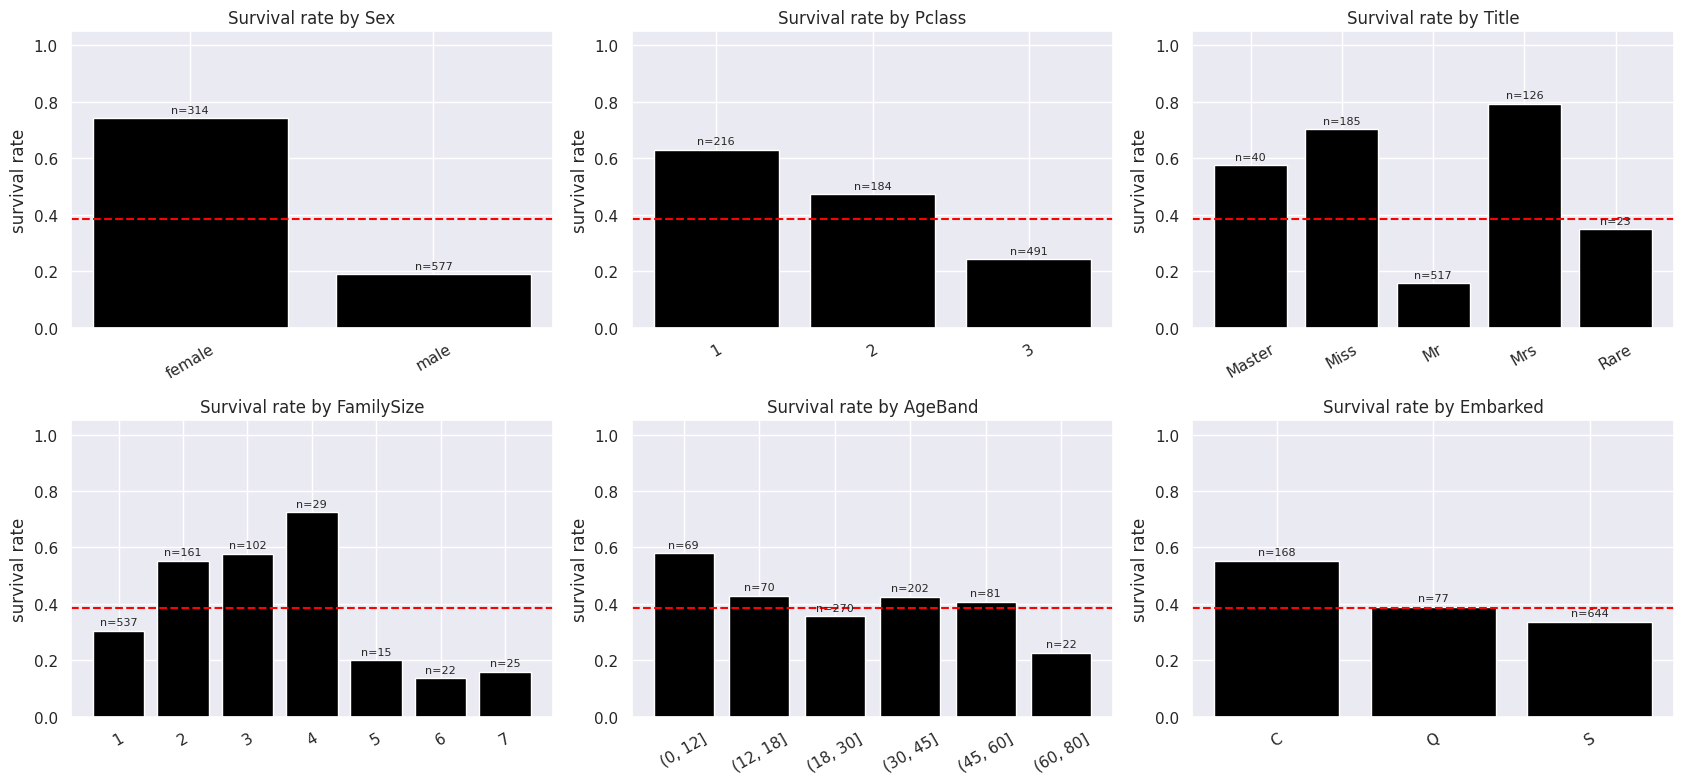

In [7]:
eda = train_raw.assign(Title=train_raw['Name'].str.extract(r',\s*([^\.]+)\.')[0].replace(RARE_TITLES, 'Rare')
                                                .replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}),
                       FamilySize=(train_raw['SibSp'] + train_raw['Parch'] + 1).clip(upper=7),
                       AgeBand=pd.cut(train_raw['Age'], [0, 12, 18, 30, 45, 60, 80]))
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.flat, ['Sex', 'Pclass', 'Title', 'FamilySize', 'AgeBand', 'Embarked']):
    rates = survival_rate(eda, col)
    ax.bar(rates.index.astype(str), rates['survival rate'], color=PALETTE['main'])
    ax.axhline(train_raw[TARGET].mean(), color=PALETTE['flag'], linestyle='--')
    for x, (rate, size) in enumerate(zip(rates['survival rate'], rates['passengers'])):
        ax.text(x, rate + 0.02, f'n={size}', ha='center', fontsize=8)
    ax.set(title=f'Survival rate by {col}', ylim=(0, 1.05), ylabel='survival rate')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [8]:
display(pd.crosstab([eda['Sex'], eda['Pclass']], eda[TARGET], normalize='index').rename(columns={0: 'died', 1: 'survived'}).round(3))

Survived        died  survived
Sex    Pclass                 
female 1       0.032     0.968
       2       0.079     0.921
       3       0.500     0.500
male   1       0.631     0.369
       2       0.843     0.157
       3       0.865     0.135

# [4/12] Features

**Aim** → turn names, cabins and families into columns a model can use, built row by row so no passenger's data leaks into another's.

**Question:** Which new columns can I build, and why these?

**Answer:** 13 columns per passenger (10 numbers, 3 categories). They become **26 model columns** after one-hot encoding (one 0/1 column per category).

| Feature | Built from | Why |
|---|---|---|
| `Title` | `Name` → Mr, Mrs, Miss, Master, Rare | sex **and** age in one word: "Master" means a boy |
| `FamilySize`, `IsAlone` | `SibSp + Parch + 1` | travelling alone and travelling as a family of 8 both hurt |
| `Deck`, `HasCabin` | first letter of `Cabin`, `U` when unknown | a recorded cabin hints at wealth and at where on the ship you slept |
| `LogFare` | $\log(1 + \text{Fare})$ | fares run from \$0 to \$512; the log stops the few expensive tickets from dominating linear models |
| `AgeMissing` | `Age` is empty | the gap itself predicts survival ([2/12]) |

- `Title` splits the passengers into 517 Mr, 185 Miss, 126 Mrs, 40 Master and 23 Rare
- deck letters shared by fewer than 10 passengers are merged into one "infrequent" column, so no column describes a handful of people

**Why there's no leakage** → each step above uses only that passenger's own row. Steps that **learn** from the data (median age, one-hot categories, scaling) sit in a pipeline and are refit inside each training fold, so the test passengers never shape them.

In [9]:
def prepare(df):
    title = (df['Name'].str.extract(r',\s*([^\.]+)\.')[0]
             .replace(RARE_TITLES, 'Rare').replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}))
    return pd.DataFrame({
        'Pclass':     df['Pclass'],
        'Age':        df['Age'],
        'SibSp':      df['SibSp'],
        'Parch':      df['Parch'],
        'FamilySize': df['SibSp'] + df['Parch'] + 1,
        'LogFare':    np.log1p(df['Fare']),
        'IsFemale':   (df['Sex'] == 'female').astype(int),
        'IsAlone':    (df['SibSp'] + df['Parch'] == 0).astype(int),
        'HasCabin':   df['Cabin'].notna().astype(int),
        'AgeMissing': df['Age'].isna().astype(int),
        'Title':      title,
        'Embarked':   df['Embarked'],
        'Deck':       df['Cabin'].str[0].fillna('U'),
    })


X      = prepare(train_raw)
X_test = prepare(test_raw)
y      = train_raw[TARGET].to_numpy()
display(X.head())
show_block('Outputs', {'X': X.shape, 'X_test': X_test.shape, 'titles': X['Title'].value_counts().to_dict()})

,Pclass,Age,SibSp,Parch,FamilySize,LogFare,IsFemale,IsAlone,HasCabin,AgeMissing,Title,Embarked,Deck
0,3,22.0,1,0,2,2.110213,0,0,0,0,Mr,S,U
1,1,38.0,1,0,2,4.280593,1,0,1,0,Mrs,C,C
2,3,26.0,0,0,1,2.188856,1,1,0,0,Miss,S,U
3,1,35.0,1,0,2,3.990834,1,0,1,0,Mrs,S,C
4,3,35.0,0,0,1,2.202765,0,1,0,0,Mr,S,U


Outputs:
    X                             (891, 13)
    X_test                        (418, 13)
    titles                        {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}


In [10]:
def make_preprocessor(scale=False):
    numeric     = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()) if scale else SimpleImputer(strategy='median')
    categorical = make_pipeline(SimpleImputer(strategy='most_frequent'),
                                OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False))
    return ColumnTransformer([('num', numeric, NUM_COLS), ('cat', categorical, CAT_COLS)], verbose_feature_names_out=False)


tree_prep     = make_preprocessor().fit(X)
feature_names = tree_prep.get_feature_names_out()
X_tree        = pd.DataFrame(tree_prep.transform(X), columns=feature_names)
show_block('Outputs', {'model matrix': X_tree.shape, 'columns': ', '.join(feature_names)})

Outputs:
    model matrix                  (891, 26)
    columns                       Pclass, Age, SibSp, Parch, FamilySize, LogFare, IsFemale, IsAlone, HasCabin, AgeMissing, Title_Master, Title_Miss, Title_Mr, Title_Mrs, Title_Rare, Embarked_C, Embarked_Q, Embarked_S, Deck_A, Deck_B, Deck_C, Deck_D, Deck_E, Deck_F, Deck_U, Deck_infrequent_sklearn


# [5/12] Baselines

**Aim** → set up one fair test for every model (the same 15 folds), and find the score every ensemble has to beat.

**Question:** What is a good score here?

**Answer:** About 82%, from plain logistic regression. That's the bar every ensemble has to clear.
- **Majority guess** → "everyone died" is already right **61.6%** of the time: the floor any model must beat
- **One rule** → "women survive, men die" reaches **78.7%** with one question
- **Logistic regression** → all features: **82.2%** accuracy, ROC-AUC **0.871**

The score moves about 2 points from fold to fold for every model → a gap below about 1 point between two models is luck of the split, not skill.

**How I score the models**

**Accuracy in one line** → the share of passengers the model gets right.

$$\text{accuracy} = \frac{\text{correct predictions}}{\text{passengers}}$$
- In short → out of all passengers, the share where "survived / died" was called right. It's the competition score

**ROC-AUC in one line** → when the model sorts passengers by its survival chance, are the survivors on top?

$$\text{ROC-AUC} = P\big(\hat p(\text{random survivor}) > \hat p(\text{random victim})\big)$$
- $\hat p$ → the model's survival chance for one passenger
- 0.5 = coin flip, 1.0 = every survivor ranked above every victim
- In short → pick one survivor and one victim at random: AUC is how often the model gives the survivor the higher chance. It only checks the order, not where the 50% cut sits

**Repeated stratified k-fold in one line** → test every model on 15 different held-out groups of passengers and average, so one lucky split can't fool me.

**How, in 4 steps**
1. **Stratified** → cut the 891 passengers into 5 folds that each keep the same 38 / 62 survived-to-died mix
2. **Fold** → train on 4 folds, test on the 5th, and rotate so every passenger is tested once
3. **Repeated** → reshuffle and cut again, `N_REPEATS` = 3 times → 15 scores per model
4. **Average** → report the mean of the 15 scores and their spread (std, how much they differ)

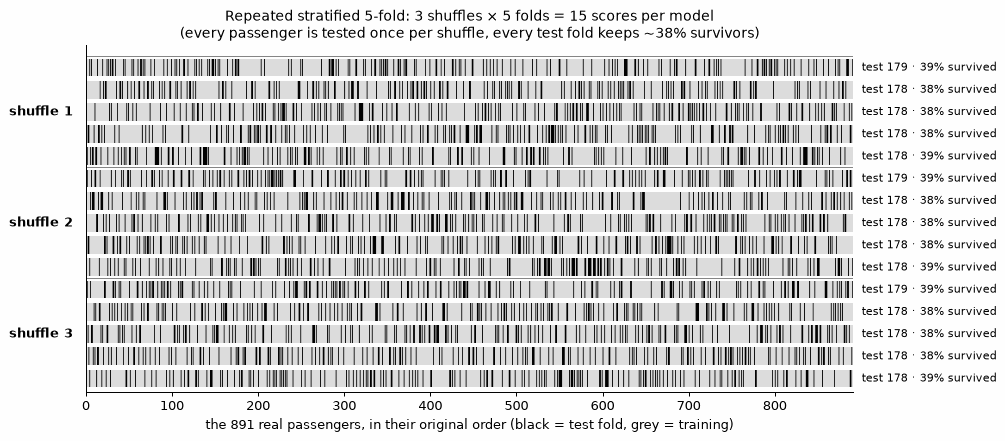

Why bother: with only 891 passengers, one lucky split can move accuracy by 3 points. 15 splits average that luck away, like tasting a soup from several spoons instead of one.

In [11]:
cv      = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
cv_once = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results = {}
models  = {}


def evaluate(name, model, family):
    scoring = ['accuracy', 'roc_auc'] if hasattr(model, 'predict_proba') else ['accuracy']
    scores  = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {'family':         family,
                     'CV accuracy':    scores['test_accuracy'].mean(),
                     'std':            scores['test_accuracy'].std(),
                     'CV ROC-AUC':     scores['test_roc_auc'].mean() if 'test_roc_auc' in scores else np.nan,
                     'train accuracy': scores['train_accuracy'].mean()}
    results[name]['overfit gap'] = results[name]['train accuracy'] - results[name]['CV accuracy']
    models[name] = model
    return results[name]


def tree_model(estimator):
    return make_pipeline(make_preprocessor(), estimator)


def scaled_model(estimator):
    return make_pipeline(make_preprocessor(scale=True), estimator)

In [12]:
baselines = {
    'Majority guess (everyone dies)': (tree_model(DummyClassifier(strategy='most_frequent')), 'baseline'),
    'One rule: women survive':        (make_pipeline(ColumnTransformer([('sex', 'passthrough', ['IsFemale'])]),
                                                     DecisionTreeClassifier(max_depth=1)), 'baseline'),
    'Logistic regression':            (scaled_model(LogisticRegression(max_iter=1000)), 'single model'),
}
for i, (name, (model, family)) in enumerate(baselines.items(), 1):
    print(f'[{i}/{len(baselines)}] {name}')
    evaluate(name, model, family)
display(pd.DataFrame(results).T.round(4))

[1/3] Majority guess (everyone dies)
[2/3] One rule: women survive
[3/3] Logistic regression


,family,CV accuracy,std,CV ROC-AUC,train accuracy,overfit gap
Majority guess (everyone dies),baseline,0.616163,0.002325,0.5,0.616162,-0.000002
One rule: women survive,baseline,0.786747,0.020904,0.766868,0.786756,0.000009
Logistic regression,single model,0.821897,0.023147,0.870687,0.836605,0.014709


# [6/12] One decision tree

**Clue** → one question, "women survive", already gets **78.7%**, and [3/12] showed that the answer to a second question (class) changes how much being a woman helped: 97% in 1st class, 50% in 3rd.

**I suspect** → a model that asks questions *one after another* is a natural fit here, and its first question will be sex.

**Question** → which question does a tree ask first, and how many in a row can it ask before it starts memorising?

**Let's break it down** → 1) score the candidate first questions by hand with Gini and information gain 2) grow trees from depth 1 to 12 3) compare the train and the cross-validated score at each depth

**Question:** How does a tree decide which question to ask first?

**A split in one line** → the tree tries every yes/no question and keeps the one that sorts the passengers into the purest groups: mostly survivors on one side, mostly victims on the other.

**How, in 4 steps**
1. **Measure the mix** → how mixed is the group before the question? (Gini or entropy, below)
2. **Try a question** → e.g. "is the passenger a woman?" → two smaller groups
3. **Measure each new group** and average them, weighted by group size
4. **Gain** = mix before − mix after. Do this for every column and threshold, and keep the biggest gain

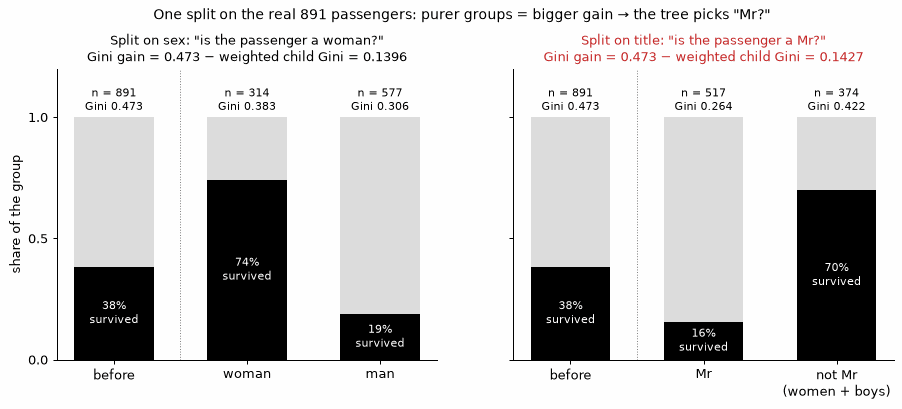

**The formulas**

$$\text{Gini}(S) = 1 - \sum_{c} p_c^2$$

**Part by part**
- $S$ → a group of passengers → the root is all 891; after a split, each side is its own $S$
- $p_c$ → the share of class $c$ in the group (survived / died) → for all 891: 38.4% survived, 61.6% died
- $p_c^2$ → the chance that two passengers drawn at random from the group *both* belong to class $c$
- $\sum_c p_c^2$ → the chance that two random passengers share a fate: $0.384^2 + 0.616^2 = 0.527$
- $1 - \dots$ → the chance that they had *different* fates: **0.473** for all 891 → 0 = everyone in the group shares one fate, 0.5 = a 50 / 50 group (the worst for two classes)
- what it means for the tree → Gini only reaches 0 when a group is pure. On 891 people with exceptions (men who survived, women who died), pure groups come only from tiny groups, so a tree left alone keeps splitting down to single passengers. That is the memorising in the depth question below
- In short → how mixed a group is: 0 when everyone in it had the same fate, highest when it's half and half

$$\text{Entropy}(S) = -\sum_{c} p_c \log_2 p_c$$
- the same job as Gini, measured in bits: how many yes/no questions you still need, on average, to learn a passenger's fate. 0 = pure, 1 bit = a 50 / 50 group
- In short → a second ruler for "how mixed". It ranks the questions here in the same order as Gini

$$\text{Gain} = \text{Impurity}(S) - \sum_{k} \frac{|S_k|}{|S|}\,\text{Impurity}(S_k)$$

**Part by part**, on the winning question "Mr?" (numbers from the picture above)
- $\text{Impurity}(S)$ → how mixed the group is *before* the question → 0.473 for all 891
- $S_k$ → the groups *after* the question → 517 Mr and 374 not-Mr (women and boys)
- $\text{Impurity}(S_k)$ → how mixed each side is → Mr 0.264 (16% survived), not-Mr 0.422 (70% survived)
- $\frac{|S_k|}{|S|}$ → the size of each side as a share → 517 / 891 and 374 / 891 → a big group counts more than a small one, so a question can't win by peeling off 3 pure passengers
- $\sum_k$ → the weighted mix after the question → 0.330
- the minus → **gain** = 0.473 − 0.330 = **0.1427**. With entropy as the impurity, it's called **information gain**
- what it means for the tree → the gain looks **one question ahead only** (greedy) and **one column at a time**. A pattern like "women survive, unless in 3rd class" has to be built from two questions in a row, and the tree never goes back to change an earlier question
- In short → how much purer the groups got thanks to the question. The question with the biggest gain is asked first

**Answer:** I was wrong: not sex, but "is the passenger a **Mr**?":
- Gini gain **0.1427** against 0.1396 for sex, and the same order by information gain (0.226 vs 0.218 bits)
- "Mr" means *adult* man, so it also moves the boys (Master, 58% survival) to the women's side; the sex split leaves them with the men. Mr survival is 16%, everyone else 70%
- class (0.049) and a recorded cabin (0.048) come a distant third

The depth-3 tree below starts with exactly this split.

In [13]:
def gini(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - np.sum(p ** 2)


def entropy(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


candidates = {'IsFemale = 1':         X['IsFemale'] == 1,
              'Title = Mr':           X['Title'] == 'Mr',
              'Pclass = 3':           X['Pclass'] == 3,
              'HasCabin = 1':         X['HasCabin'] == 1,
              'Age < 10':             X['Age'] < 10,
              'LogFare > median':     X['LogFare'] > X['LogFare'].median()}
rows = {}
for name, mask in candidates.items():
    mask = mask.to_numpy()
    rows[name] = {'yes': mask.sum(), 'survival if yes': y[mask].mean(), 'survival if no': y[~mask].mean(),
                  'Gini gain': gini(y) - (mask.mean() * gini(y[mask]) + (~mask).mean() * gini(y[~mask])),
                  'information gain': entropy(y) - (mask.mean() * entropy(y[mask]) + (~mask).mean() * entropy(y[~mask]))}
show_block('Outputs', {'Gini (all passengers)': f'{gini(y):.4f}', 'entropy (all passengers)': f'{entropy(y):.4f} bits'})
display(pd.DataFrame(rows).T.sort_values('Gini gain', ascending=False).round(4))

Outputs:
    Gini (all passengers)         0.4730
    entropy (all passengers)      0.9607 bits


,yes,survival if yes,survival if no,Gini gain,information gain
Title = Mr,517.0,0.1567,0.6979,0.1427,0.2263
IsFemale = 1,314.0,0.7420,0.1889,0.1396,0.2177
Pclass = 3,491.0,0.2424,0.5575,0.0491,0.0758
HasCabin = 1,204.0,0.6667,0.2999,0.0475,0.0711
LogFare > median,444.0,0.5180,0.2506,0.0358,0.0554
Age < 10,62.0,0.6129,0.3667,0.0078,0.0116


**Question:** How deep should the tree grow?

**Tree depth in one line** → how many questions in a row the tree may ask before it must answer. More questions → smaller and smaller groups, down to single passengers.

**Answer:** **Depth 4**, at 81.6% cross-validated accuracy.
- deeper → training accuracy keeps climbing (96% at depth 12) while cross-validated accuracy drifts down to 80.3%
- unlimited → 98.9% on the passengers it trained on, **78.9%** on new ones: below the one-rule model

**What to look for** in the chart below → the gap between the train line and the cross-validated line. It grows with depth, and for the unlimited tree it reaches 20 points. That gap is pure memorisation (**overfitting**), like a student who learns last year's answers by heart and then fails the new exam.

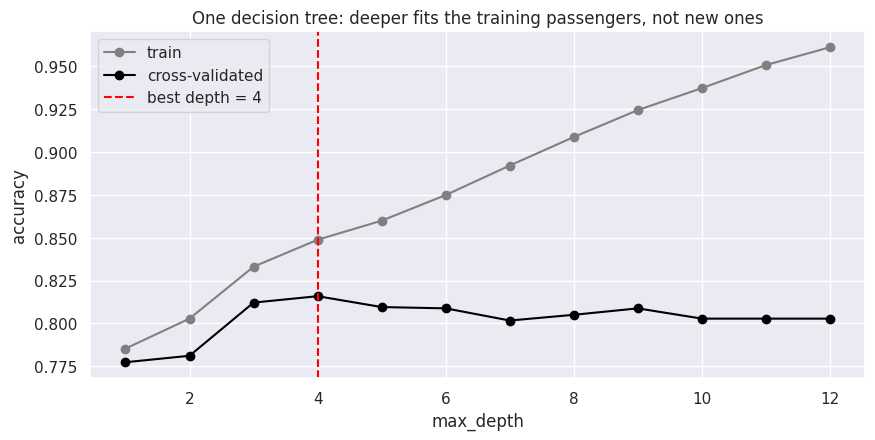

,1,2,3,4,5,6,7,8,9,10,11,12
train accuracy,0.785,0.803,0.833,0.849,0.86,0.875,0.892,0.909,0.925,0.937,0.951,0.961
CV accuracy,0.777,0.781,0.812,0.816,0.81,0.809,0.802,0.805,0.809,0.803,0.803,0.803


In [14]:
depth_rows = {}
for depth in TREE_DEPTHS:
    scores = cross_validate(tree_model(DecisionTreeClassifier(max_depth=depth, random_state=SEED)), X, y, cv=cv,
                            scoring='accuracy', return_train_score=True, n_jobs=-1)
    depth_rows[depth] = {'train accuracy': scores['train_score'].mean(), 'CV accuracy': scores['test_score'].mean()}
depth_table = pd.DataFrame(depth_rows).T
best_depth  = int(depth_table['CV accuracy'].idxmax())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(depth_table.index, depth_table['train accuracy'], marker='o', color=PALETTE['soft'], label='train')
ax.plot(depth_table.index, depth_table['CV accuracy'], marker='o', color=PALETTE['main'], label='cross-validated')
ax.axvline(best_depth, color=PALETTE['flag'], linestyle='--', label=f'best depth = {best_depth}')
ax.set(xlabel='max_depth', ylabel='accuracy', title='One decision tree: deeper fits the training passengers, not new ones')
ax.legend()
plt.show()
display(depth_table.T.round(3))

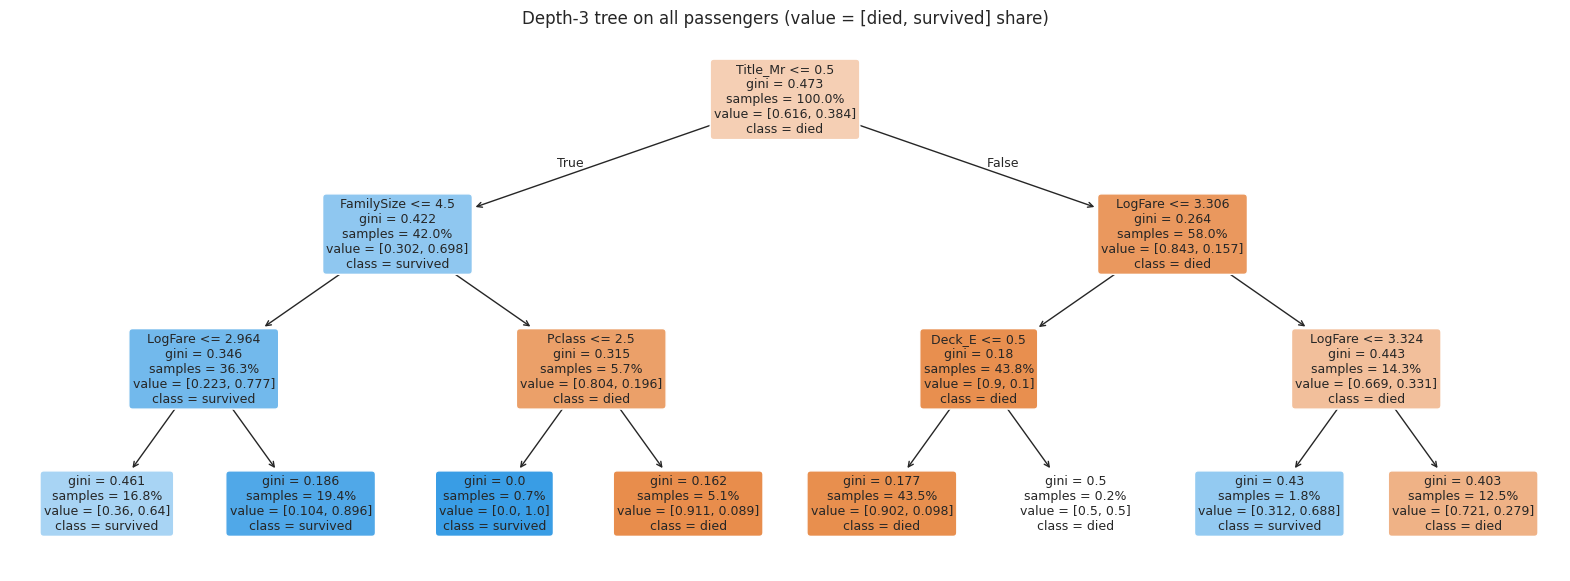

In [15]:
evaluate(f'Decision tree (depth {best_depth})', tree_model(DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)), 'single model')
evaluate('Decision tree (unlimited)', tree_model(DecisionTreeClassifier(random_state=SEED)), 'single model')
small_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_tree, y)
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(small_tree, feature_names=feature_names, class_names=['died', 'survived'], filled=True, impurity=True,
          proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Depth-3 tree on all passengers (value = [died, survived] share)')
plt.show()

**Something odd** → depth 4 wins, but a few more questions and the score already slips, while the training score keeps climbing. A tree seems to care a lot about exactly which passengers it saw.

**Question:** If one tree is decent, why is it not enough?

**What I do** → grow 25 full trees, each on a slightly different random sample of the same 712 training passengers (a bootstrap sample, see [8/12]), and ask them all about the same 179 validation passengers.

**Answer:** One tree changes its mind too easily:
- the 25 trees score anywhere from **74.9% to 84.4%** on the same passengers
- they don't all agree on **69.3%** of those passengers
- yet their **majority vote scores 83.2%**, better than almost any of them alone

That disagreement between trees is exactly what an ensemble feeds on.

In [16]:
train_idx, val_idx = next(cv_once.split(X, y))
prep_fold = make_preprocessor().fit(X.iloc[train_idx])
X_fit, X_val = prep_fold.transform(X.iloc[train_idx]), prep_fold.transform(X.iloc[val_idx])
rng   = np.random.default_rng(SEED)
votes = np.array([DecisionTreeClassifier(random_state=k).fit(X_fit[s], y[train_idx][s]).predict(X_val)
                  for k, s in enumerate(rng.integers(0, len(train_idx), size=(25, len(train_idx))))])
single_acc   = (votes == y[val_idx]).mean(axis=1)
share_yes    = votes.mean(axis=0)
show_block('Outputs', {'validation passengers':           len(val_idx),
                       'single-tree accuracy (range)':    f'{single_acc.min():.3f} - {single_acc.max():.3f}',
                       'not unanimous':                   f'{((share_yes > 0) & (share_yes < 1)).mean():.1%}',
                       'majority vote of the 25 trees':   f'{((share_yes > 0.5) == y[val_idx]).mean():.3f}'})

Outputs:
    validation passengers         179
    single-tree accuracy (range)  0.749 - 0.844
    not unanimous                 69.3%
    majority vote of the 25 trees 0.832


# [7/12] Ensemble learning

**Clue** → the 25 trees in [6/12] score anywhere from 74.9% to 84.4% and disagree on 69.3% of the passengers, yet their majority vote scores **83.2%**, better than almost any of them alone.

**I'm curious** → how can a vote of shaky trees beat the trees themselves? **I suspect** it works only because they make **different** mistakes.

**Question** → what kinds of ensembles exist, and how far can a crowd go?

**Let's break it down** → 1) sort the ways to combine models 2) work out the theory of a majority vote (Condorcet) 3) put the 25 real trees next to it

**Question:** What kinds of ensembles exist?

**Answer:** 4 kinds, sorted by two questions: are the members trained **in parallel** (each on its own) or **in sequence** (each one fixes the last), and are they the **same algorithm** or **different ones**?

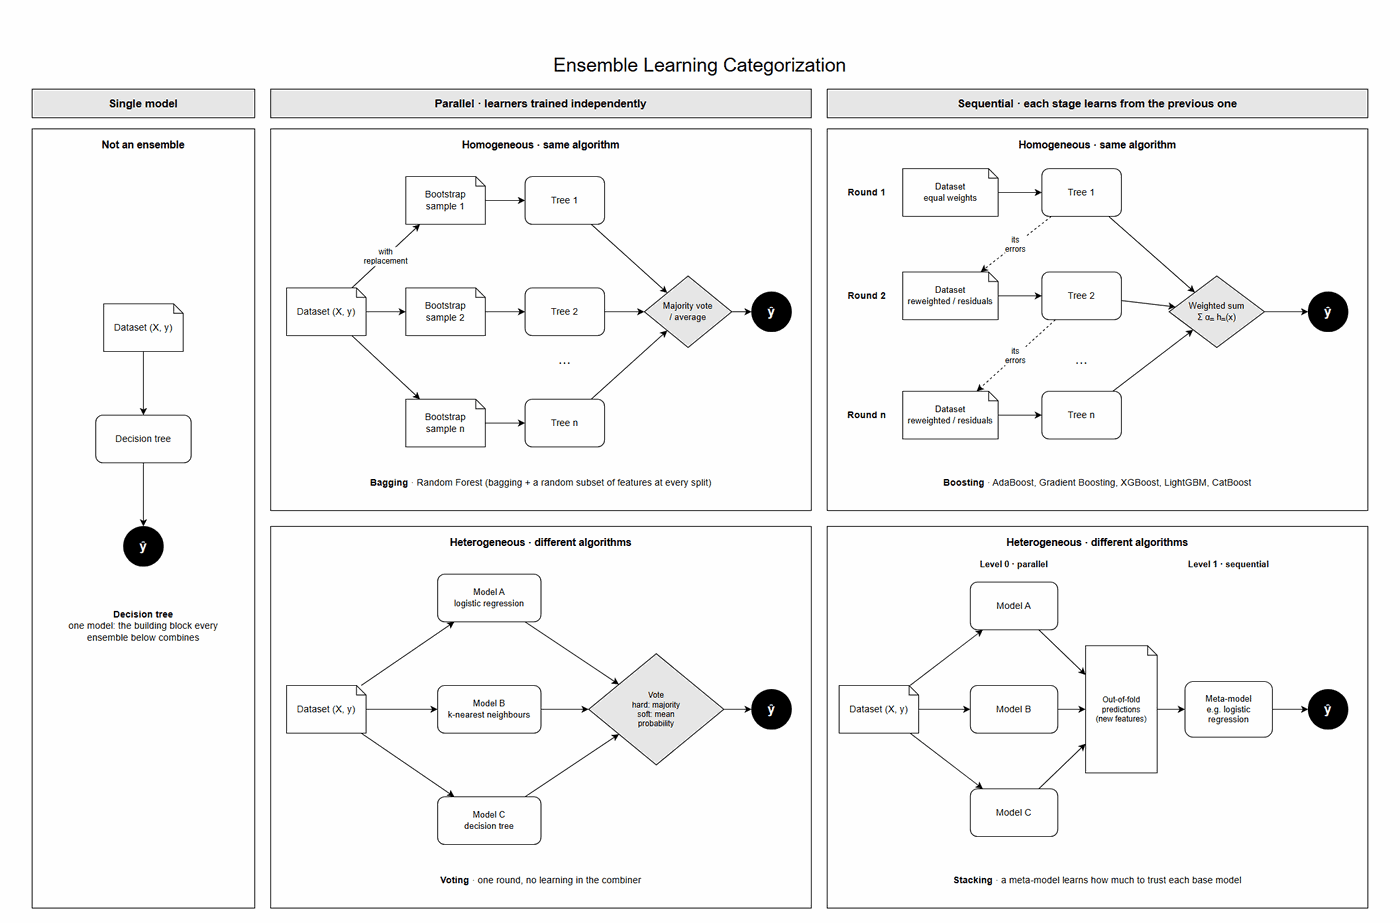

| | Parallel | Sequential |
|---|---|---|
| **Same algorithm** | **Bagging / Random Forest** → many trees on bootstrap samples, majority vote → lowers **variance** | **Boosting** → each tree focuses on what the previous ones got wrong, weighted sum → lowers **bias** |
| **Different algorithms** | **Voting** → logistic regression, k-NN, trees… vote once | **Stacking** → base models in parallel, then a meta-model learns how far to trust each |

- **Variance** → the model is jumpy: small changes in the data change its answers, like the 25 trees above. Averaging calms it
- **Bias** → the model is too simple and wrong in the same way every time, like a one-question tree. Adding fixes one by one helps

**Question:** Why should a crowd of so-so models beat one good one?

**A story first** → in 1906 Francis Galton asked 787 visitors at a country fair to guess the weight of an ox. No single guess was reliable, but the **median guess was 1,207 lb, against a true 1,198 lb**. The errors pointed in different directions and cancelled out.

**Condorcet's jury theorem in one line** → if each voter is right more often than wrong, and the voters don't copy each other, a majority vote gets more accurate with every voter you add.

**How, in 3 steps**
1. Each of $n$ voters is right with chance $p$ (above 50%), on their own
2. The vote is right when more than half of them are right
3. With more voters, a wrong vote needs more and more voters to be wrong *at the same time*, which gets very unlikely

$$P(\text{majority correct}) = \sum_{k > n/2}^{n} \binom{n}{k}\, p^k (1-p)^{n-k}$$

**Part by part**
- $n$ → number of voters (models) → odd, so there's no tie
- $p$ → the accuracy of each voter on its own → must be **above 0.5**: below it the same formula runs the other way and adding voters makes the vote *worse*
- $p^k (1-p)^{n-k}$ → one particular way for $k$ voters to be right and the rest wrong → multiplying the chances is only allowed when the voters are **independent**. That's the assumption real models break: trees trained on the same passengers fail on the same passengers
- $\binom{n}{k}$ → how many ways to pick which $k$ voters are the right ones
- $\sum_{k > n/2}$ → adds up every case where **more than half** are right
- the catch → 25 copies of the same model are one voter. The real gain sits somewhere between one voter and $n$ independent ones, depending on how alike they are
- In short → add up the chances of every "majority is right" outcome. With independent voters the total races towards 100%; asking the same person 25 times is still one opinion

**Answer:** In theory, 51 independent voters that are each right 65% of the time would be right together **98.6%** of the time. The 25 real trees reach only **83.2%** (red star in the chart below), because they learned from the same passengers and repeat many of the same mistakes.

→ My guess was right: the vote helps because the trees disagree, and it stops helping where they agree. That gap between the curve and the star is the whole story of ensembles: the gain is limited by **how alike the members are**, and every method below is a different way to make them less alike.

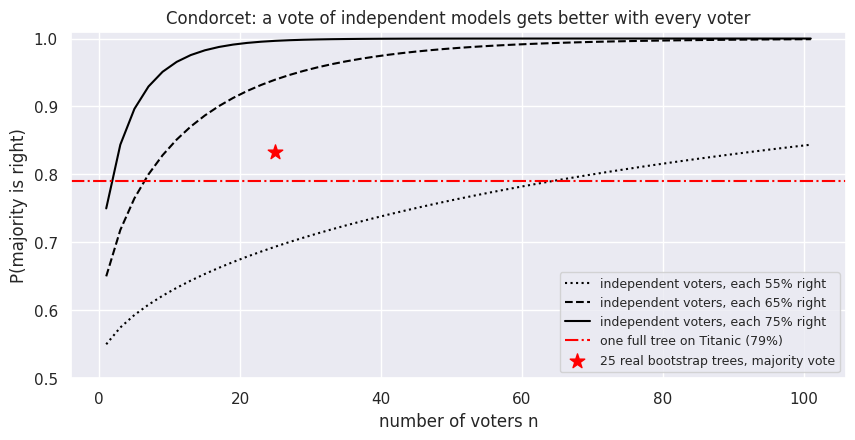

Outputs:
    51 independent voters at 65%  0.986
    25 real trees (correlated)    0.832


In [17]:
voters = np.arange(1, 102, 2)
fig, ax = plt.subplots(figsize=(10, 4.5))
for p, style in [(0.55, ':'), (0.65, '--'), (0.75, '-')]:
    majority = [binom.sf(n // 2, n, p) for n in voters]
    ax.plot(voters, majority, linestyle=style, color=PALETTE['main'], label=f'independent voters, each {p:.0%} right')
ax.axhline(single_acc.mean(), color=PALETTE['flag'], linestyle='-.', label=f'one full tree on Titanic ({single_acc.mean():.0%})')
ax.scatter([25], [((share_yes > 0.5) == y[val_idx]).mean()], s=120, marker='*', color=PALETTE['flag'], zorder=3,
           label='25 real bootstrap trees, majority vote')
ax.set(xlabel='number of voters n', ylabel='P(majority is right)', ylim=(0.5, 1.01),
       title='Condorcet: a vote of independent models gets better with every voter')
ax.legend(fontsize=9)
plt.show()
show_block('Outputs', {'51 independent voters at 65%': f'{binom.sf(25, 51, 0.65):.3f}',
                       '25 real trees (correlated)':  f'{((share_yes > 0.5) == y[val_idx]).mean():.3f}'})

# [8/12] Bagging and Random Forest

**Clue** → in theory 51 independent voters at 65% would be right 98.6% of the time; the 25 real trees stop at 83.2%, because they learned from the same passengers and repeat the same mistakes.

**I suspect** → how alike the trees are (their correlation) sets a ceiling that more trees can't break, and hiding columns from them (Random Forest) should lower it, because then the trees can't all reach for the same strongest question ("Mr?").

**Question** → how far can averaging calm a jumpy tree, and does hiding columns really make the trees less alike?

**Let's break it down** → 1) how bootstrap makes many training sets out of one 2) what the bagging variance formula says, part by part 3) accuracy against the number of trees 4) measure the tree correlation ρ 5) sweep the number of columns per split

**Question:** How can a model get more training sets out of one dataset?

**Bootstrap in one line** → make a "new" training set by drawing 891 passengers out of the 891, putting each one back after it's drawn.

**How, in 3 steps**
1. Draw one passenger at random, write them down, put them back
2. Repeat 891 times → some passengers show up 2 or 3 times, about a third never show up
3. The ones left out are **out-of-bag** (OOB): a free test set for that tree, no extra fold needed

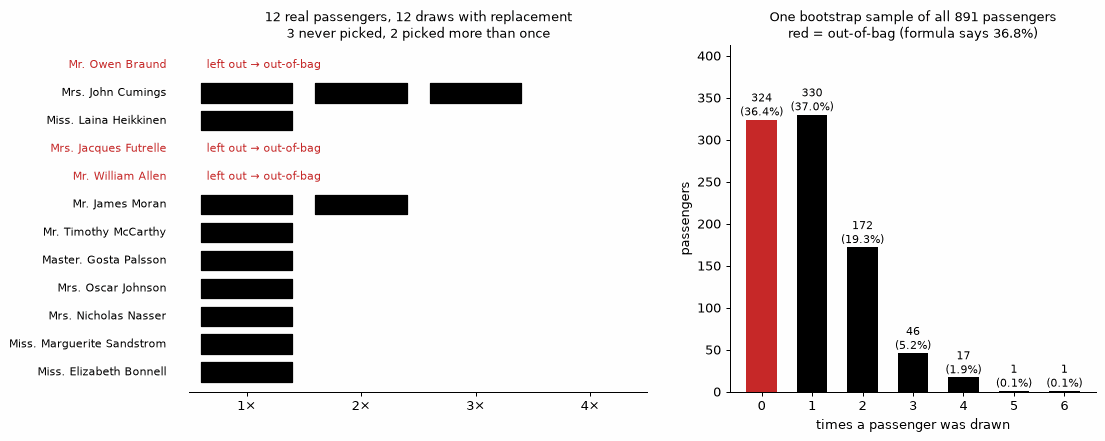

$$P(\text{passenger left out of one bootstrap sample}) = \Big(1 - \frac{1}{n}\Big)^n \;\xrightarrow{n \to \infty}\; e^{-1} \approx 36.8\%$$
- $n$ → number of passengers (891)
- $1 - \frac{1}{n}$ → the chance one passenger is *not* picked in one draw
- to the power $n$ → not picked in any of the $n$ draws
- In short → each passenger has about a 1 in 3 chance (36.8%) to sit out a given tree. Like a raffle where tickets go back in the drum after each draw: some names are called twice, some never

**Bagging in one line** → grow one full tree per bootstrap sample and let them vote. Each tree is jumpy, but their jumps partly cancel out.

**Why averaging helps, and where it stops**
1. One tree's prediction wobbles from sample to sample: that wobble is its variance $\sigma^2$
2. Average $B$ trees → the part of the wobble they *don't* share shrinks with every tree
3. The part they *do* share, because they learned from the same passengers, never goes away

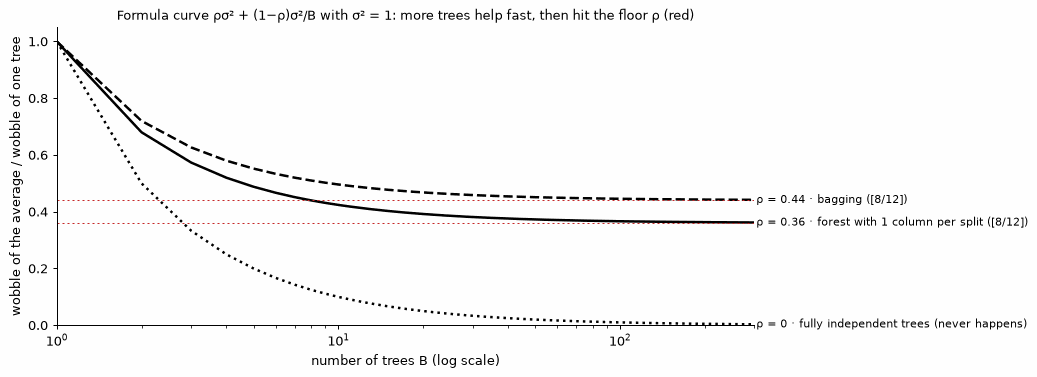

The picture just draws the formula below with $\sigma^2 = 1$ and the $\rho$ values measured further down; the real accuracy curves come after the next cells.

$$\text{Var}\big(\bar h\big) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$

**Part by part**
- $\text{Var}(\bar h)$ → how much the **average** of $B$ trees wobbles from one training sample to the next → the lower, the steadier the forest's answers
- $\sigma^2$ → how much **one** tree wobbles → big for a full-depth tree (the 25 trees in [6/12] range from 74.9% to 84.4%). Bagging uses full trees on purpose: they have little bias and lots of variance, and variance is the part averaging can remove
- $\rho$ → how alike two trees are (correlation: 0 = unrelated, 1 = identical), measured as Breiman did: how alike their right / wrong records are over the validation passengers → it comes from the shared data: every bootstrap sample holds about 63% of the same 891 passengers, so the trees see largely the same people and can all reach for the same strong column ("Mr?")
- $\frac{1-\rho}{B}\sigma^2$ → the wobble the trees **don't** share → divided by $B$, so more trees shrink it fast and then barely: with $\rho = 0.44$ and $\sigma^2 = 1$ it is 0.056 at 10 trees and 0.002 at 300. That's the jump from 78.3% (1 tree) to 82.4% (10 trees), then the flat line
- $\rho\,\sigma^2$ → the wobble they **share** → no $B$ in it, so no number of trees touches it → **correlation sets the floor**: 0.44 of one tree's wobble for bagging, however many trees
- how Random Forest attacks it → more trees can't lower the floor, so it lowers $\rho$ instead: with only √p random columns per split, trees can't all ask "Mr?" first. The price: each tree gets weaker, so $\sigma^2$ (and the bias) can go up. It only pays if $\rho$ falls more than the trees weaken
- In short → more trees help fast at first, then stop at a floor set by how alike the trees are. To go lower you need *less alike* trees, not more of them

**Random Forest in one line** → bagging, plus at every split each tree may only look at a few random columns, so the trees can't all ask the same questions.

**How, in 3 steps**
1. Draw a bootstrap sample, like bagging
2. At every split, pick a random $\sqrt{p}$ of the $p$ columns: √26 ≈ 5 of the 26 here
3. Choose the best question among those 5 only. Sometimes "Mr?" is in the draw; sometimes the tree has to make do with a much weaker column

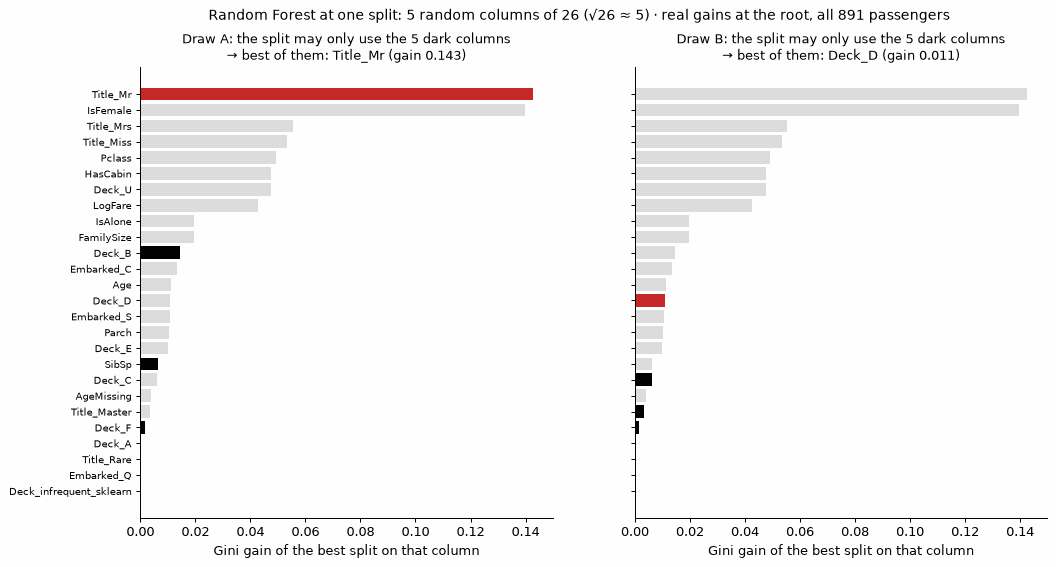

The hope: trees that don't all start with "Mr?" are less alike → lower $\rho$ → lower floor.

**Answer:**
- **Bootstrap** → $(1 - 1/891)^{891} = 0.3677$, and 200 real bootstrap samples leave out 36.76% ± 1.1% of the passengers, exactly as the formula says
- **Out-of-bag** → the forest's OOB accuracy (82.6%) lands close to its 15-fold accuracy (82.1%) at no extra cost
- **More trees** → both methods jump from 78.3% with 1 tree to 82.4% with 10, then level off: **83.6%** for bagging, **82.5%** for Random Forest at 300 trees
- **Correlation** → I was wrong about √p: on Titanic it does **not** make the trees less alike: ρ = 0.43 against 0.44 for bagging, so Random Forest has no variance to win back and ends slightly behind

In [18]:
n_rows  = len(X)
oob     = [(1 - np.isin(np.arange(n_rows), rng.integers(0, n_rows, n_rows))).mean() for _ in range(200)]
show_block('Outputs', {'(1 - 1/n)^n for n = 891':    f'{(1 - 1 / n_rows) ** n_rows:.4f}',
                       'left out, 200 real samples':  f'{np.mean(oob):.4f} ± {np.std(oob):.4f}'})

Outputs:
    (1 - 1/n)^n for n = 891       0.3677
    left out, 200 real samples    0.3676 ± 0.0109


In [19]:
def staged_vote_curves(estimator):
    curve, corr = np.zeros(N_TREES), []
    for train_idx, val_idx in cv_once.split(X, y):
        fitted = tree_model(clone(estimator)).fit(X.iloc[train_idx], y[train_idx])
        X_val  = fitted[0].transform(X.iloc[val_idx])
        feats  = getattr(fitted[-1], 'estimators_features_', [slice(None)] * N_TREES)
        probs  = np.array([tree.predict_proba(X_val[:, f])[:, 1] for tree, f in zip(fitted[-1].estimators_, feats)])
        curve += ((np.cumsum(probs, axis=0) / np.arange(1, N_TREES + 1)[:, None] > 0.5) == y[val_idx]).mean(axis=1)
        c      = np.corrcoef(np.where((probs > 0.5) == y[val_idx], 1.0, -1.0))
        corr.append(c[np.triu_indices_from(c, k=1)].mean())
    return curve / N_FOLDS, float(np.mean(corr))


forest_variants = {
    'Bagging (all columns per split)': BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=RF_PARAMS['min_samples_leaf']),
                                                         n_estimators=N_TREES, random_state=SEED),
    'Random Forest (√p columns per split)': RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS),
}
curves, correlations = {}, {}
for i, (name, estimator) in enumerate(forest_variants.items(), 1):
    print(f'[{i}/{len(forest_variants)}] {name}')
    curves[name], correlations[name] = staged_vote_curves(estimator)

[1/2] Bagging (all columns per split)
[2/2] Random Forest (√p columns per split)


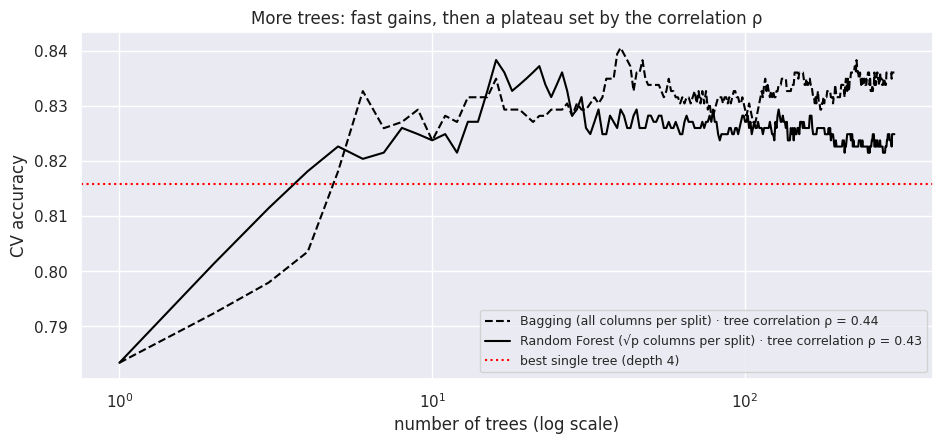

,1 tree,10 trees,300 trees,tree correlation ρ
Bagging (all columns per split),0.783,0.824,0.836,0.436
Random Forest (√p columns per split),0.783,0.824,0.825,0.434


In [20]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for (name, curve), style in zip(curves.items(), ['--', '-']):
    ax.plot(np.arange(1, N_TREES + 1), curve, linestyle=style, color=PALETTE['main'], label=f'{name} · tree correlation ρ = {correlations[name]:.2f}')
ax.axhline(results[f'Decision tree (depth {best_depth})']['CV accuracy'], color=PALETTE['flag'], linestyle=':', label=f'best single tree (depth {best_depth})')
ax.set(xscale='log', xlabel='number of trees (log scale)', ylabel='CV accuracy', title='More trees: fast gains, then a plateau set by the correlation ρ')
ax.legend(fontsize=9)
plt.show()
display(pd.DataFrame({'1 tree': {k: v[0] for k, v in curves.items()}, '10 trees': {k: v[9] for k, v in curves.items()},
                      f'{N_TREES} trees': {k: v[-1] for k, v in curves.items()}, 'tree correlation ρ': correlations}).round(3))

**Something odd** → hiding columns was supposed to lower ρ, but with √p = 5 columns ρ barely moved (0.43 vs 0.44), and Random Forest ended behind plain bagging.

**Question:** Random Forest's only change is the number of columns per split. Where is its sweet spot on this data?

**Answer:** A U-shape, with the default near the bottom: **1 column per split** scores best (84.1%) with the least alike trees (ρ = 0.36); √p = 5 columns scores 82.5%; all 26 columns (plain bagging) 83.6%.

**Why**
- the signal sits in a few columns (title, sex, class). With 5 random columns a split often has to do without the best one, so each tree gets weaker, but it usually finds a close substitute (`Title_Mr` ↔ `IsFemale`), so the trees stay just as alike
- with 1 column per split the trees become almost random, truly different from each other, and the vote of 300 of them recovers the signal

These numbers come from one 5-fold split, and differences of about 1 point are within its noise → √p is a sensible default, not a law. The knob is worth tuning on each dataset.

In [21]:
sweep = {}
for i, k in enumerate([1, 2, 3, 5, 8, 13, 20, None], 1):
    print(f'[{i}/8] columns per split = {k or "all"}')
    curve, rho = staged_vote_curves(RandomForestClassifier(n_estimators=N_TREES, max_features=k, random_state=SEED,
                                                           min_samples_leaf=RF_PARAMS['min_samples_leaf']))
    sweep[k or X_tree.shape[1]] = {'CV accuracy': curve[-1], 'tree correlation ρ': rho}
sweep = pd.DataFrame(sweep).T

[1/8] columns per split = 1
[2/8] columns per split = 2
[3/8] columns per split = 3
[4/8] columns per split = 5
[5/8] columns per split = 8
[6/8] columns per split = 13
[7/8] columns per split = 20
[8/8] columns per split = all


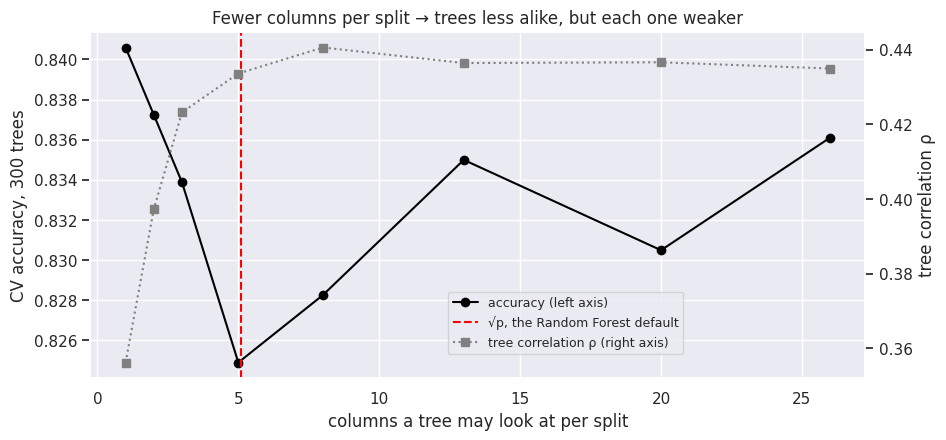

,1,2,3,5,8,13,20,26
CV accuracy,0.841,0.837,0.834,0.825,0.828,0.835,0.830,0.836
tree correlation ρ,0.356,0.397,0.423,0.434,0.441,0.436,0.437,0.435


In [22]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sweep.index, sweep['CV accuracy'], marker='o', color=PALETTE['main'], label='accuracy (left axis)')
ax.axvline(np.sqrt(X_tree.shape[1]), color=PALETTE['flag'], linestyle='--', label='√p, the Random Forest default')
ax.set(xlabel='columns a tree may look at per split', ylabel=f'CV accuracy, {N_TREES} trees',
       title='Fewer columns per split → trees less alike, but each one weaker')
ax2 = ax.twinx()
ax2.plot(sweep.index, sweep['tree correlation ρ'], marker='s', linestyle=':', color=PALETTE['soft'], label='tree correlation ρ (right axis)')
ax2.set_ylabel('tree correlation ρ')
ax2.grid(False)
fig.legend(loc='lower center', bbox_to_anchor=(0.6, 0.15), fontsize=9)
plt.show()
display(sweep.T.round(3))

In [23]:
evaluate('Bagging', tree_model(forest_variants['Bagging (all columns per split)']), 'bagging')
evaluate('Random Forest', tree_model(RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS)), 'bagging')
oob_forest = tree_model(RandomForestClassifier(n_estimators=N_TREES, oob_score=True, random_state=SEED, **RF_PARAMS)).fit(X, y)
show_block('Outputs', {'Random Forest OOB accuracy': f'{oob_forest[-1].oob_score_:.4f}',
                       'Random Forest CV accuracy':  f'{results["Random Forest"]["CV accuracy"]:.4f}'})

Outputs:
    Random Forest OOB accuracy    0.8260
    Random Forest CV accuracy     0.8208


# [9/12] Boosting

**Clue** → averaging hits a floor: bagging levels off at 83.6% after about 10 trees, and the bagging formula says why. It removes the wobble the trees don't share, but a mistake *every* tree makes stays in the average.

**I'm curious** → what if the trees were trained one after another instead of side by side, each one aimed at the passengers the earlier ones got wrong?

**Question** → can a chain of small trees fix the mistakes a crowd shares, and what stops it from memorising?

**Let's break it down** → 1) run AdaBoost by hand for 3 rounds and watch the weights 2) follow gradient boosting's residuals 3) compare learning rates from 0.01 to 1.0 4) score AdaBoost, Gradient Boosting and XGBoost on the 15 folds

**Question:** How does AdaBoost decide which passengers deserve more attention?

**AdaBoost in one line** → train a tiny tree, make the passengers it got wrong heavier, train the next tiny tree on that, and repeat; at the end every tree votes, the better ones louder.

**How, in 4 steps**
1. **Start equal** → every passenger has the same weight, 1/891
2. **Train a stump** (a tree with one question) using those weights, and find its weighted error ε: the share of the weight sitting on the passengers it got wrong
3. **Give it a say** α → low error = big say; close to a coin flip = almost none
4. **Reweight** → the passengers it got wrong get heavier, the rest lighter, so the next stump has to care about the mistakes. Back to step 2

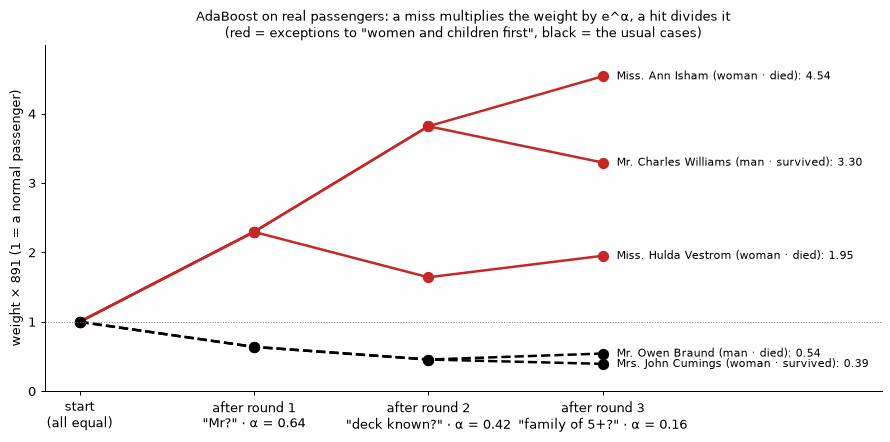

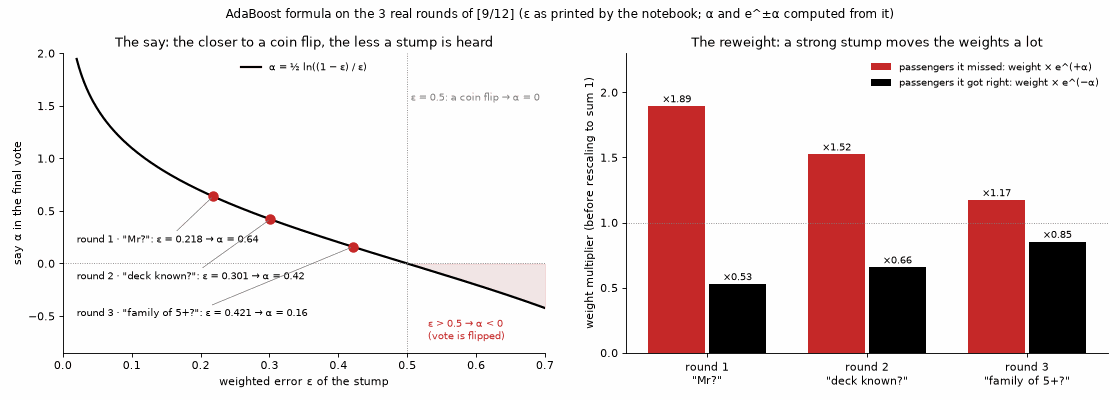

*Computed by me from the 3 weighted errors ε this notebook prints below: α = ½ ln((1 − ε) / ε) and the multipliers e^±α.*

$$\varepsilon_m = \sum_{i:\,h_m(x_i) \ne y_i} w_i \qquad \alpha_m = \tfrac12 \ln\frac{1 - \varepsilon_m}{\varepsilon_m} \qquad w_i \leftarrow w_i \, e^{\pm\alpha_m}$$

**Part by part**
- $w_i$ → the weight of passenger $i$ → starts equal ($1/891$) and is rescaled to sum to 1 after every round, so it reads as "the share of attention" this passenger gets
- $h_m$ → stump number $m$ → one question only, so it can't memorise anyone; the attention comes from the weights, not from depth
- $\varepsilon_m = \sum_{\text{missed}} w_i$ → the **weighted** error (step 2): not "how many passengers it missed" but "how much weight sits on them" → missing a heavy passenger costs more than missing a light one
- $\frac{1 - \varepsilon_m}{\varepsilon_m}$ → the odds of being right → round 1: 0.782 / 0.218 = 3.6 to 1
- $\tfrac12 \ln(\dots)$ → turns those odds into the say $\alpha_m$ (step 3) → 0.64, 0.42, 0.16 in the 3 rounds; exactly 0 for a coin flip ($\varepsilon = 0.5$), and **negative** if $\varepsilon > 0.5$: a stump worse than a coin gets its vote flipped
- $e^{+\alpha_m}$ / $e^{-\alpha_m}$ → the reweight (step 4) → round 1 multiplies the missed passengers' weight by about 1.9 and the others' by about 0.53. After rescaling, the missed passengers hold exactly half the weight, because $\varepsilon\,e^{\alpha} = (1-\varepsilon)\,e^{-\alpha}$: that's where the 50% in the answer comes from
- final prediction → $\text{sign}\big(\sum_m \alpha_m h_m(x)\big)$ → a weighted vote, the better stumps louder
- the weak spot → the weight grows **exponentially** each time a passenger is missed. Passengers no column explains (a man who survived, a woman who died) are missed round after round and can end up steering the later stumps. On Titanic the stumps keep this in check: train and validation stay within 1 point
- In short → each stump gets a say based on how good it was, and a passenger's weight grows every time they're missed. Hard passengers pile up weight, easy ones fade

**Answer:** Each round has a harder job and gets less say:

| Round | The stump asks | ε | α |
|---|---|---|---|
| 1 | "is the passenger a Mr?" | 0.218 | 0.64 |
| 2 | "is the deck known?" | 0.301 | 0.42 |
| 3 | "family of 5 or more?" | 0.421 | 0.16, barely better than a coin, so barely heard |

After every update the passengers just missed hold exactly **50%** of the weight, so the next stump can't ignore them. After 3 rounds the surprising cases dominate: women who died are 9% of the passengers but carry 18% of the weight; men who survived go from 12% → 25%.

In [24]:
weights, rounds = np.full(len(y), 1 / len(y)), {}
for m in range(1, 4):
    stump   = DecisionTreeClassifier(max_depth=1).fit(X_tree, y, sample_weight=weights)
    miss    = stump.predict(X_tree) != y
    eps     = weights[miss].sum()
    alpha   = 0.5 * np.log((1 - eps) / eps)
    weights = weights * np.exp(np.where(miss, alpha, -alpha))
    weights = weights / weights.sum()
    rounds[f'round {m}'] = {'split': f'{feature_names[stump.tree_.feature[0]]} ≤ {stump.tree_.threshold[0]:.2f}',
                            'weighted error ε': round(eps, 4), 'say α': round(alpha, 4), 'passengers missed': int(miss.sum()),
                            'weight on the missed after update': round(weights[miss].sum(), 4)}
display(pd.DataFrame(rounds).T)
groups = train_raw['Sex'] + np.where(y == 1, ' · survived', ' · died')
display(pd.DataFrame({'share of passengers': groups.value_counts(normalize=True),
                      'share of weight after round 3': pd.Series(weights).groupby(groups.to_numpy()).sum()}).round(3))

,split,weighted error ε,say α,passengers missed,weight on the missed after update
round 1,Title_Mr ≤ 0.50,0.2177,0.6395,194,0.5
round 2,Deck_U ≤ 0.50,0.3007,0.4219,274,0.5
round 3,FamilySize ≤ 4.50,0.4206,0.1601,507,0.5


,share of passengers,share of weight after round 3
female · died,0.091,0.180
female · survived,0.262,0.189
male · died,0.525,0.380
male · survived,0.122,0.251


**Question:** How does gradient boosting improve step by step, and what does the learning rate do?

**Gradient boosting in one line** → start with one guess for everyone, then add small trees one by one, each trained on what's still wrong (the residuals), taking only a small step each time.

**How, in 4 steps**
1. **Start** → every passenger gets the overall survival chance, 38.4%
2. **Residual** → how far off is each guess? A survivor at 0.38 is off by +0.62, a victim at 0.38 by −0.38
3. **Fit a small tree** (depth 3) to those residuals → it learns *which kinds* of passengers are still guessed too high or too low
4. **Take a small step** → add only $\nu$ (the learning rate, here 0.05) times the tree's answer, then back to step 2

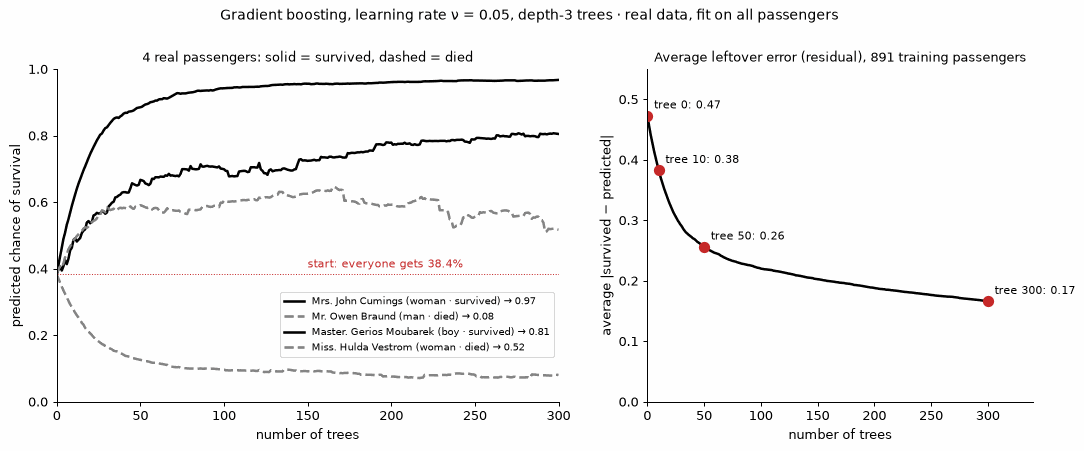

$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x) \qquad h_m \approx -\frac{\partial L}{\partial F} = y - \hat p_{m-1}(x)$$

**Part by part**
- $F_m(x)$ → the model's **log-odds** of survival for passenger $x$ after $m$ trees → a score from −∞ to +∞ that becomes a chance with $\hat p = 1 / (1 + e^{-F})$. Adding trees in log-odds keeps every chance between 0 and 1
- $F_{m-1}(x)$ → everything learned so far → it starts as the same guess for everyone, 38.4% (log-odds about −0.47), and is never retrained: each new tree only adds to it
- $y - \hat p_{m-1}(x)$ → the **residual**, what's still wrong → +0.62 for a survivor at 0.38, −0.38 for a victim. It's also minus the slope (gradient) of the log loss $L$, which gives the method its name: each tree takes a step downhill on the loss
- $h_m(x)$ → a small depth-3 tree fitted to those residuals (steps 2-3) → it finds *groups* of passengers still guessed too high or too low. Small trees keep the bias down slowly instead of memorising in one go
- $\nu$ → the **learning rate**: only this share of each tree's answer is kept (step 4) → small $\nu$ = many small careful steps, big $\nu$ = few big steps that overshoot
- $m$, the number of trees → every tree shrinks the training error a bit more (the average leftover error falls from 0.47 to 0.17 by tree 300, in the picture), including the error on passengers no column explains → with too many trees for the step size, the model starts fitting noise. $\nu$ and the number of trees have to be tuned together
- In short → new guess = old guess + a small step that fixes part of the leftover error. Small steps need many trees but rarely overshoot; big steps get there fast and then chase noise, like tuning a guitar string with big twists instead of small ones

**Answer:** The learning rate trades speed for safety:
- **ν = 0.05** → the highest peak, 85.1% at tree 204, still 84.5% at 300
- **ν = 0.01** → still climbing at 300 trees (83.6%): too careful for this budget
- **ν = 0.2** → peaks early (84.7% at tree 76), then decays to 82.4%
- **ν = 1.0** → peaks at tree 2 (82.3%) and falls to 77.2% while training accuracy reaches 92-97%: every tree overshoots
- **AdaBoost with stumps** → train and validation stay within 1 point: a stump is too simple to memorise anyone

Over the 15 folds: Gradient Boosting **83.5%**, XGBoost 83.3%, AdaBoost 82.7%. Gradient boosting leads the family, but with a 10-point gap between train and validation accuracy.

In [25]:
def staged_boosting(make_estimator):
    val_curve, train_curve = np.zeros(N_TREES), np.zeros(N_TREES)
    for train_idx, val_idx in cv_once.split(X, y):
        fitted = tree_model(make_estimator()).fit(X.iloc[train_idx], y[train_idx])
        X_fit, X_val = fitted[0].transform(X.iloc[train_idx]), fitted[0].transform(X.iloc[val_idx])
        val_curve   += np.array([(p == y[val_idx]).mean() for p in fitted[-1].staged_predict(X_val)])
        train_curve += np.array([(p == y[train_idx]).mean() for p in fitted[-1].staged_predict(X_fit)])
    return val_curve / N_FOLDS, train_curve / N_FOLDS


boost_curves = {}
for i, lr in enumerate(LEARNING_RATES, 1):
    print(f'[{i}/{len(LEARNING_RATES)}] gradient boosting · learning rate {lr}')
    boost_curves[lr] = staged_boosting(lambda: GradientBoostingClassifier(n_estimators=N_TREES, random_state=SEED,
                                                                         **{**GB_PARAMS, 'learning_rate': lr}))
print('[+] AdaBoost · stumps')
ada_curve = staged_boosting(lambda: AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=N_TREES,
                                                      random_state=SEED, **ADA_PARAMS))

[1/4] gradient boosting · learning rate 0.01
[2/4] gradient boosting · learning rate 0.05
[3/4] gradient boosting · learning rate 0.2
[4/4] gradient boosting · learning rate 1.0
[+] AdaBoost · stumps


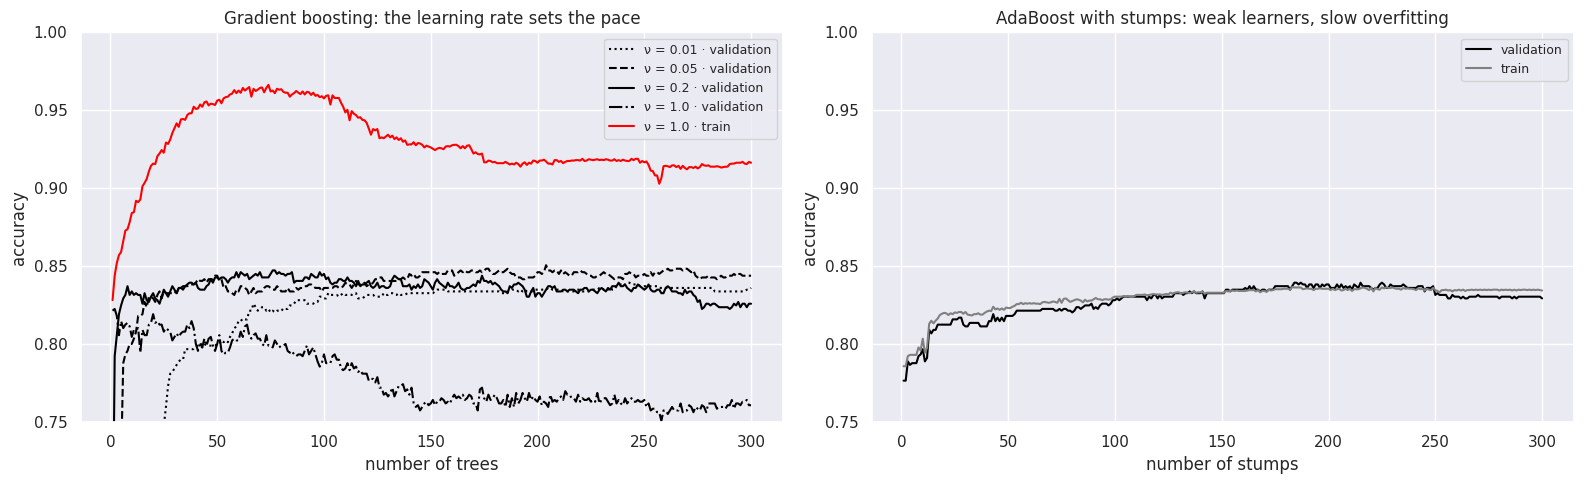

,ν = 0.01,ν = 0.05,ν = 0.2,ν = 1.0
best validation,0.839,0.851,0.847,0.823
at tree,242.000,204.000,76.000,2.000
validation at 300,0.836,0.844,0.826,0.761
train at 300,0.869,0.931,0.983,0.916


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for (lr, (val, train)), style in zip(boost_curves.items(), [':', '--', '-', '-.']):
    axes[0].plot(np.arange(1, N_TREES + 1), val, linestyle=style, color=PALETTE['main'], label=f'ν = {lr} · validation')
lr_max = max(LEARNING_RATES)
axes[0].plot(np.arange(1, N_TREES + 1), boost_curves[lr_max][1], color=PALETTE['flag'], label=f'ν = {lr_max} · train')
axes[0].set(xlabel='number of trees', ylabel='accuracy', title='Gradient boosting: the learning rate sets the pace', ylim=(0.75, 1.0))
axes[0].legend(fontsize=9)
axes[1].plot(np.arange(1, N_TREES + 1), ada_curve[0], color=PALETTE['main'], label='validation')
axes[1].plot(np.arange(1, N_TREES + 1), ada_curve[1], color=PALETTE['soft'], label='train')
axes[1].set(xlabel='number of stumps', ylabel='accuracy', title='AdaBoost with stumps: weak learners, slow overfitting', ylim=(0.75, 1.0))
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
display(pd.DataFrame({f'ν = {lr}': {'best validation': val.max(), 'at tree': int(val.argmax()) + 1, f'validation at {N_TREES}': val[-1],
                                     f'train at {N_TREES}': train[-1]} for lr, (val, train) in boost_curves.items()}).round(3))

In [27]:
boosters = {
    'AdaBoost (stumps)': tree_model(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=N_TREES, random_state=SEED, **ADA_PARAMS)),
    'Gradient Boosting': tree_model(GradientBoostingClassifier(n_estimators=N_TREES, random_state=SEED, **GB_PARAMS)),
    'XGBoost':           tree_model(XGBClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=1, **XGB_PARAMS)),
}
for i, (name, model) in enumerate(boosters.items(), 1):
    print(f'[{i}/{len(boosters)}] {name}')
    evaluate(name, model, 'boosting')
display(pd.DataFrame(results).T.loc[list(boosters)].round(4))

[1/3] AdaBoost (stumps)
[2/3] Gradient Boosting
[3/3] XGBoost


,family,CV accuracy,std,CV ROC-AUC,train accuracy,overfit gap
AdaBoost (stumps),boosting,0.826765,0.020632,0.868689,0.836792,0.010027
Gradient Boosting,boosting,0.835367,0.019574,0.87667,0.933314,0.097947
XGBoost,boosting,0.833499,0.021222,0.875894,0.903947,0.070449


# [10/12] Voting and Stacking

**Clue** → very different models end up close on the 15 folds: Gradient Boosting 83.5%, Bagging 83.3%, AdaBoost 82.7%, Random Forest 82.1%, plain logistic regression 82.2% back in [5/12].

**I suspect** → they are right and wrong on mostly the same passengers, so letting them vote won't add much.

**Question** → do different algorithms make different mistakes, and is a simple vote or a learned mix the better way to combine them?

**Let's break it down** → 1) correlate the 4 base models' out-of-fold mistakes 2) hard vs soft vote 3) a stacking meta-model that learns whom to trust

**Question:** Do different algorithms make different mistakes?

A vote only helps where the members disagree. The heatmap below compares each pair of models' out-of-fold mistakes (mistakes on passengers the model didn't train on): 1 = they always fail on the same passengers, 0 = unrelated failures.

**Answer:** Not very. Their mistakes correlate **0.64-0.81**: the two tree ensembles overlap most (0.81), k-NN and Gradient Boosting least (0.64).
- **97 passengers fool all 4 models**, and 91 of them are men who survived (62) or women who died (29): the exceptions to "women and children first" that no column explains
- only 124 passengers split the models → a vote can fix at most those 124, and only where the majority happens to be right

→ My suspicion holds: the models overlap a lot, so the room for a vote is small.

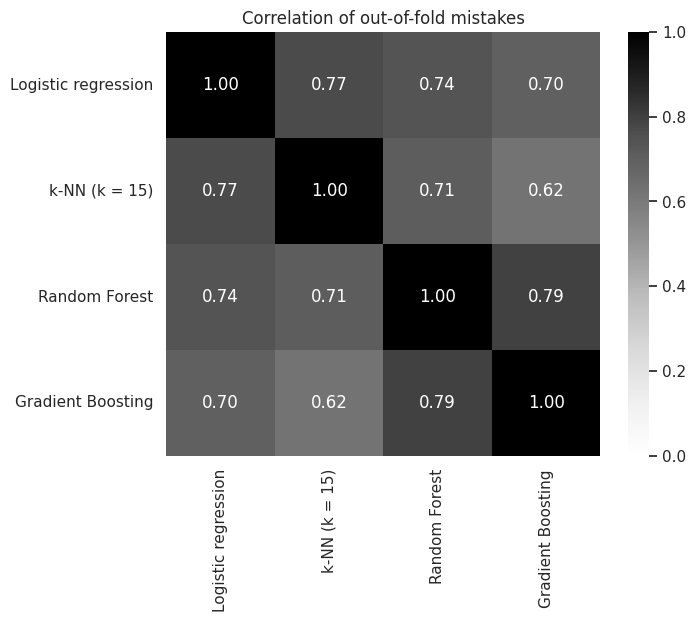

Outputs:
    accuracy per model            {'Logistic regression': 0.822, 'k-NN (k = 15)': 0.818, 'Random Forest': 0.825, 'Gradient Boosting': 0.844}
    passengers all 4 get wrong    95
    passengers some get wrong     127


In [28]:
base_models = {
    'Logistic regression': scaled_model(LogisticRegression(max_iter=1000)),
    'k-NN (k = 15)':       scaled_model(KNeighborsClassifier(n_neighbors=15)),
    'Random Forest':       tree_model(RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, **RF_PARAMS)),
    'Gradient Boosting':   tree_model(GradientBoostingClassifier(n_estimators=N_TREES, random_state=SEED, **GB_PARAMS)),
}
oof_probs = pd.DataFrame({name: cross_val_predict(model, X, y, cv=cv_once, method='predict_proba', n_jobs=-1)[:, 1]
                          for name, model in base_models.items()})
mistakes  = (oof_probs > 0.5).astype(int).ne(y, axis=0).astype(int)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(mistakes.corr(), annot=True, fmt='.2f', cmap='Greys', vmin=0, vmax=1, ax=ax)
ax.set_title('Correlation of out-of-fold mistakes')
plt.show()
show_block('Outputs', {'accuracy per model':        (1 - mistakes.mean()).round(3).to_dict(),
                       'passengers all 4 get wrong': int((mistakes.sum(axis=1) == 4).sum()),
                       'passengers some get wrong':  int(((mistakes.sum(axis=1) > 0) & (mistakes.sum(axis=1) < 4)).sum())})

**Question:** Should the models simply vote, or learn whom to trust?

**Voting in one line** → every model predicts, and the most popular answer wins.
- **Hard vote** → each model says "survived" or "died", one vote each
- **Soft vote** → each model hands in its survival chance; I average them and cut at 0.5, so a sure model counts more than a hesitant one

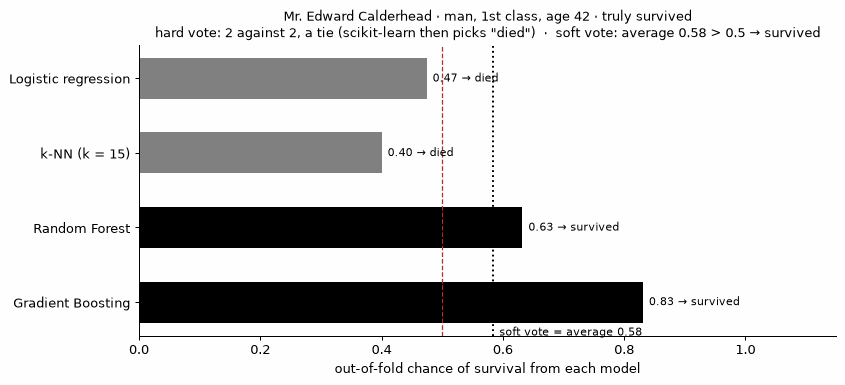

$$\text{hard vote: } \hat y = \text{mode}\{h_1(x), \dots, h_K(x)\} \qquad \text{soft vote: } \hat y = \Big[\tfrac1K \sum_{k} \hat p_k(x) > 0.5\Big]$$

**Part by part**
- $h_k(x)$ → model $k$'s answer for passenger $x$, survived or died; $K$ → number of models (4)
- $\text{mode}\{\dots\}$ → the most common answer → a confident model and a hesitant one count the same, and with 4 models a 2-2 tie can happen
- $\hat p_k(x)$ → model $k$'s survival chance → the soft vote uses *how sure* each model is → it trusts these chances to mean the same thing across models (k-NN's 0.6 and Gradient Boosting's 0.6); badly calibrated chances skew the average
- $\tfrac1K \sum_k$ → a plain average → **every model gets the same weight, 1/4** → three weaker models can outvote the strongest one, which is what the answer below finds
- $> 0.5$ → the cut: above it "survived"
- the condition behind both → a vote can only fix passengers on whom the models **disagree**: 124 here, against 97 that fool all 4
- In short → hard = count the hands; soft = average how sure everyone is. On a 2-2 tie the hard vote can't decide, while the soft vote follows the models that are most sure

**Stacking in one line** → instead of equal votes, train a small model (the meta-model) on the base models' predictions, so it learns how much to trust each one.

**How, in 3 steps**
1. **Out-of-fold predictions** → split the passengers into 5 folds; each base model trains on 4 folds and predicts the 5th, until every passenger has a prediction from models that never saw them
2. **New table** → 891 rows × 4 columns: one survival chance per base model
3. **Meta-model** → a logistic regression learns from that table how to mix the 4 chances; its coefficients say whom to trust

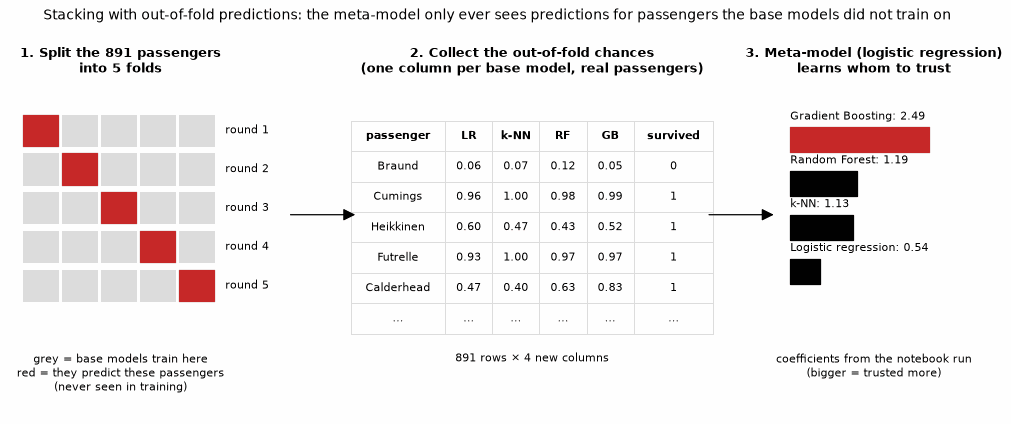

The probabilities in these two pictures come from a local rerun of the same 4 models; the coefficients are the ones this notebook prints.

**Why out-of-fold** → predictions on passengers a model trained on look far too good (the unlimited tree is 98.9% right on them). Trained on those, the meta-model would trust the biggest memoriser.

$$\text{stacking: } \hat y = g\big(\hat p_1(x), \dots, \hat p_K(x)\big) \qquad \text{here } g = \text{sigmoid}\Big(w_0 + \sum_{k} w_k\, \hat p_k(x)\Big)$$

**Part by part**
- $\hat p_k(x)$ → base model $k$'s **out-of-fold** survival chance (step 1) → from a model that never saw passenger $x$, so the meta-model learns how the base models do on *new* passengers
- $w_k$ → the weight the meta-model gives model $k$ → learned from the 891-row table (step 2) instead of fixed at 1/4 → this replaces the equal weights that hurt the vote
- $w_0$ → the intercept → shifts the cut, so it no longer has to sit at an average of 0.5
- $\text{sigmoid}(\dots)$ → turns the weighted sum back into a chance between 0 and 1
- the weak spot → the 4 inputs are strongly alike (mistakes correlate 0.64-0.81), so the weights say *who to trust more*, not an exact share; and without out-of-fold predictions the meta-model would trust the biggest memoriser (see above)
- In short → a second model learns the mix: how much of each base model's chance to use, learned from data instead of fixed at 1/4 each

**Answer:**
- **Voting** → hard 83.1%, soft 83.0%: both *below* their best member, Gradient Boosting (83.5%). Equal votes let the three weaker models outvote it on the passengers where it alone is right (hard voting has no probability, so no ROC-AUC)
- **Stacking** → the meta-model learns this from data: Gradient Boosting gets the largest coefficient (**2.49**), about twice Random Forest (1.19) and k-NN (1.13), and 4.6× logistic regression (0.54). Result: **83.4%** with the smallest fold spread of every model (std 1.7 points), a tie with Gradient Boosting at lower risk

In [29]:
named_bases = list(base_models.items())
combiners   = {
    'Voting (hard)': VotingClassifier(named_bases, voting='hard'),
    'Voting (soft)': VotingClassifier(named_bases, voting='soft'),
    'Stacking':      StackingClassifier(named_bases, final_estimator=LogisticRegression(max_iter=1000), cv=N_FOLDS, stack_method='predict_proba'),
}
for i, (name, model) in enumerate(combiners.items(), 1):
    print(f'[{i}/{len(combiners)}] {name}')
    evaluate(name, model, 'voting / stacking')
stack_full = clone(combiners['Stacking']).fit(X, y)
display(pd.DataFrame({'meta-model coefficient': stack_full.final_estimator_.coef_[0]}, index=list(base_models)).round(3))
display(pd.DataFrame(results).T.loc[list(combiners)].round(4))

[1/3] Voting (hard)
[2/3] Voting (soft)
[3/3] Stacking


,meta-model coefficient
Logistic regression,0.542
k-NN (k = 15),1.125
Random Forest,1.167
Gradient Boosting,2.518


,family,CV accuracy,std,CV ROC-AUC,train accuracy,overfit gap
Voting (hard),voting / stacking,0.829768,0.018384,NaN,0.891415,0.061647
Voting (soft),voting / stacking,0.82976,0.01869,0.878925,0.890572,0.060813
Stacking,voting / stacking,0.835005,0.015964,0.87904,0.905912,0.070907


# [11/12] Leaderboard

**Clue** → stacking (83.4%) ties Gradient Boosting (83.5%), and the best model of each family lands within about a point of the others, while one model's score moves about 2 points from fold to fold ([5/12]).

**Question** → is there a real winner at all, or only a tie? And whichever comes first, what does it lean on?

**Let's break it down** → 1) rank every model on the same 15 folds with its spread 2) compare the overfit gaps 3) shuffle one column at a time on the top model (permutation importance)

**Question:** Which model wins, and by how much?

**Answer:** No clear winner. Gradient Boosting 83.5%, Stacking 83.4%, Bagging 83.3%, XGBoost 83.3%: the top 4 lie within 0.15 points, while each one's score moves 1.5-2.5 points from fold to fold → a **statistical tie**, not a ranking.

**What the table does show** (`overfit gap` = train accuracy − cross-validated accuracy: how much a model memorised rather than learned)
- every ensemble beats the best single tree (81.6%) and the unlimited tree (78.9%)
- logistic regression (82.2%) is hard to beat: the best ensembles add about 1 point
- the overfit gap tells the families apart: unlimited tree 20 points, bagging and gradient boosting 10, AdaBoost and logistic regression 1-1.5

→ The submission uses the top row (Gradient Boosting); Stacking is the steadier choice with the smallest spread.

,CV accuracy,std,CV ROC-AUC,train accuracy,overfit gap,family
Gradient Boosting,0.8354,0.0196,0.8767,0.9333,0.0979,boosting
Stacking,0.8350,0.0160,0.8790,0.9059,0.0709,voting / stacking
XGBoost,0.8335,0.0212,0.8759,0.9039,0.0704,boosting
Bagging,0.8331,0.0154,0.8722,0.9364,0.1033,bagging
Voting (hard),0.8298,0.0184,NaN,0.8914,0.0616,voting / stacking
Voting (soft),0.8298,0.0187,0.8789,0.8906,0.0608,voting / stacking
AdaBoost (stumps),0.8268,0.0206,0.8687,0.8368,0.0100,boosting
Logistic regression,0.8219,0.0231,0.8707,0.8366,0.0147,single model
Random Forest,0.8208,0.0152,0.8753,0.9108,0.0900,bagging
Decision tree (depth 4),0.8159,0.0225,0.8484,0.8489,0.0329,single model


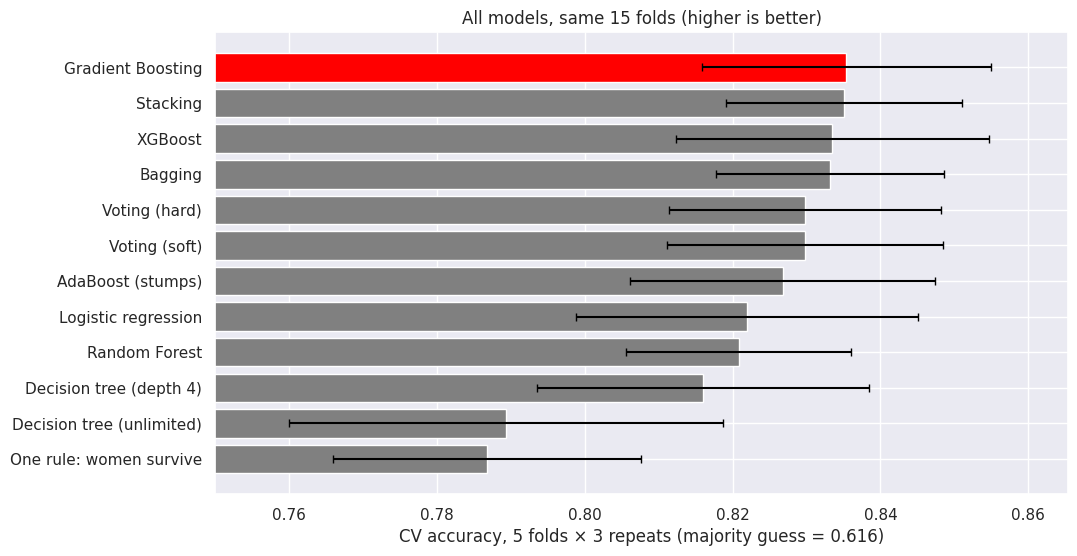

In [30]:
leaderboard = pd.DataFrame(results).T.sort_values('CV accuracy', ascending=False)
display(leaderboard.drop(columns='family').astype(float).round(4).assign(family=leaderboard['family']))
ranked = leaderboard.drop(index='Majority guess (everyone dies)').sort_values('CV accuracy')
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(ranked.index, ranked['CV accuracy'].astype(float), xerr=ranked['std'].astype(float), capsize=3,
        color=[PALETTE['flag'] if name == leaderboard.index[0] else PALETTE['soft'] for name in ranked.index])
ax.set(xlabel=f'CV accuracy, {N_FOLDS} folds × {N_REPEATS} repeats (majority guess = {results["Majority guess (everyone dies)"]["CV accuracy"]:.3f})',
       xlim=(0.75, ranked['CV accuracy'].max() + 0.03), title='All models, same 15 folds (higher is better)')
plt.show()

**Question:** What does the winning model rely on?

**I suspect** → the title: the very first split in [6/12] was "Mr?", and the first AdaBoost stump in [9/12] asked the same.

**Permutation importance in one line** → mix up one column so it no longer belongs to the right passenger, and see how much accuracy drops. A big drop = the model leans on that column.

**How, in 4 steps**
1. Score the trained model on its validation passengers
2. Shuffle one column (e.g. `Title`) across those passengers; every other column stays as it was
3. Score again: the drop in accuracy is that column's importance
4. Repeat 10 times per column and over the 5 folds, and average

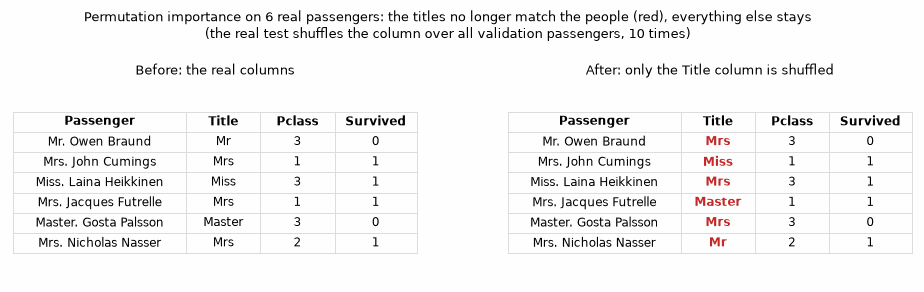

**Answer:** I was right, **Title** dominates: shuffling it costs **13.6 points** of accuracy, about 3× more than sex alone (4.7), because the title already holds sex *and* age group. Then class (3.8), age (3.6), fare (3.3) and family size (2.3). `HasCabin`, `Deck`, `IsAlone` and `SibSp` sit at or slightly below zero: once title, class and fare are known, they add nothing the model can still use.

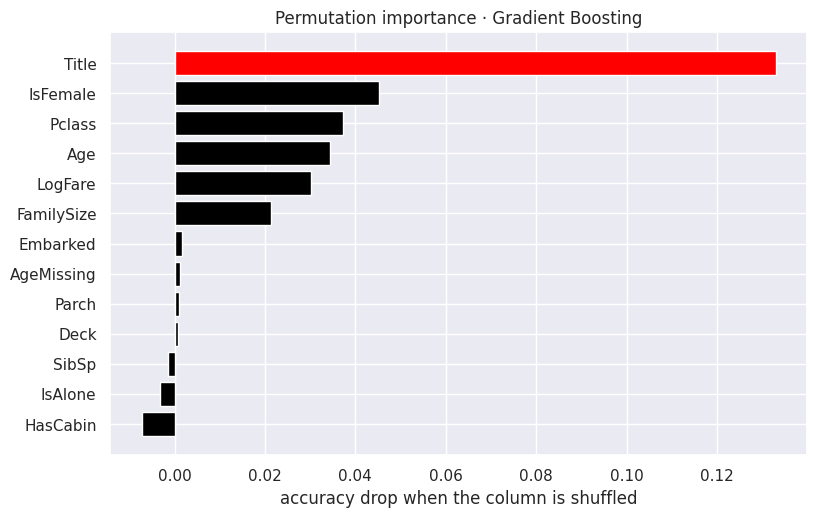

In [31]:
best_name   = leaderboard.index[0]
importances = []
for train_idx, val_idx in cv_once.split(X, y):
    fitted = clone(models[best_name]).fit(X.iloc[train_idx], y[train_idx])
    result = permutation_importance(fitted, X.iloc[val_idx], y[val_idx], n_repeats=10, random_state=SEED, scoring='accuracy', n_jobs=-1)
    importances.append(result.importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance.index, importance, color=[PALETTE['flag'] if v == importance.max() else PALETTE['main'] for v in importance])
ax.set(xlabel='accuracy drop when the column is shuffled', title=f'Permutation importance · {best_name}')
plt.show()

# [12/12] Submission

**Aim** → refit the winner on all 891 passengers and predict the 418 test passengers. It only previews unless you turn it on.

**Question:** How would this score on the leaderboard?

**Answer:** Set `SAVE_SUBMISSION = True` to write `submission.csv` for all 418 test passengers. The cross-validated accuracy above is the best local estimate; the public leaderboard scores about half of the test set, so expect a few points of luck either way.

In [32]:
"""Optional · Set SAVE_SUBMISSION = True in the top cell to write the CSV."""
show_block('Inputs', {'mode':        'save' if SAVE_SUBMISSION else 'preview',
                      'model':       best_name,
                      'train rows':  len(X),
                      'test rows':   len(X_test),
                      'output file': SUBMISSION_FILE})

Inputs:
    mode                          preview
    model                         Gradient Boosting
    train rows                    891
    test rows                     418
    output file                   /kaggle/working/submission.csv


In [33]:
final_model = clone(models[best_name]).fit(X, y)
submission  = pd.DataFrame({'PassengerId': test_raw['PassengerId'], TARGET: final_model.predict(X_test).astype(int)})
display(submission.head(SUBMISSION_PREVIEW))
show_block('Outputs', {'predicted survivors': f'{submission[TARGET].sum()} of {len(submission)} ({submission[TARGET].mean():.1%})'})

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


Outputs:
    predicted survivors           151 of 418 (36.1%)


In [34]:
if SAVE_SUBMISSION:
    submission.to_csv(SUBMISSION_FILE, index=False)
    print(f'Saved → {SUBMISSION_FILE}')
else:
    print(f'Preview · {len(submission)} rows · nothing written (SAVE_SUBMISSION = False)')

Preview · 418 rows · nothing written (SAVE_SUBMISSION = False)


**Next steps**

- **Leaderboard check** → submit with `SAVE_SUBMISSION = True` and compare the public score with the cross-validated 83.5%
- **Ticket groups** → passengers sharing a ticket travelled together and often shared a fate; a group survival feature, built inside each fold
- **More randomness** → [8/12] says 1 column per split works best here: try `ExtraTreesClassifier` and `max_features` = 1-2
- **Tuning** → randomised search over learning rate × depth × number of trees for gradient boosting, inside nested cross-validation
- **Calibration** → check whether a soft-vote probability of 0.7 really means 7 in 10 survive